<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/21_QKD_Attack_Detection/QSVM_CVQKDAttackDetection_Ding2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM and QNN for CV-QKD attack detection: Ding et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Chao Ding, Shi Wang, Jingtao Sun, Yaonan Wang, Daoyi Dong and Weibo Gao, "Noise-Resistant Feature-Aware Attack Detection
> Using Quantum Machine Learning", arXiv:2601.06762 (quant-ph), January 2026. https://arxiv.org/abs/2601.06762

The paper publishes no code and no data, and the version we have contains no appendix (it is cited three times for the
datasets, but is not in the PDF). Everything below is written from the 14-page description, with the software the paper
names: PennyLane (`default.qubit` and `default.mixed`) for the quantum part.

**The problem in plain words.** In continuous-variable quantum key distribution (CV-QKD) Alice sends laser pulses whose
amplitude is random (Gaussian) and Bob measures them with a homodyne detector. An eavesdropper can attack not the
quantum channel but Bob's *equipment* (blind the detector, change the strength of the reference laser called the local
oscillator, saturate the detector, ...). Such attacks leave fingerprints in six simple statistics of every block of
received pulses: mean, variance, entropy and range of Bob's data, the local-oscillator power, and the shot-noise level.
The paper trains a quantum support-vector machine (QSVM) or a quantum neural network (QNN) on these six numbers to say
which attack, if any, is running, *before* the secret key is distilled.

**What the notebook does.**
1. It builds a physics-based simulator of CV-QKD blocks (Gaussian modulation, lossy channel, homodyne detection) with
   five known attacks (the paper's NA, HA, LA, CA, SA, BA) and five invented "unknown" attacks (U1 to U5), because the
   authors' data cannot be downloaded.
2. It extracts the paper's six features per block, standardises them (training split only) and encodes each block on
   **six qubits**, one feature per qubit, with the six feature maps of the paper (three angle encodings AnRx/AnRy/AnRz and
   three IQP encodings IQPl/IQPc/IQPf).
3. It trains the six QSVM variants (quantum kernel + one-against-the-rest SVM) and six QNN variants (variational circuit,
   softmax on Pauli-Z expectations, Adam), and redraws Figs. 5 to 9.
4. It builds the paper's three "physically interpretable noise backends" (bit flip, amplitude damping, phase damping,
   depolarizing noise from Table 1), checks our fast noisy kernel against PennyLane's mixed-state simulator, and redraws
   Tables 2 to 5.
5. It trains classical baselines on the identical six standardised features, and ends with a side-by-side table of the
   paper's numbers and ours, a verdict per claim, a critical reading and exercises.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
a pinned PennyLane; if Colab asks to restart the session, do so and run all cells again. With `FAST_MODE = True` the
notebook finishes in a few minutes; the full setting (`FAST_MODE = False`) trains all twelve variants for 45 epochs and
takes about an hour on a CPU. No GPU, no IBM account and no download are needed: the data are generated inside the notebook.

**What you get at the end.** The twelve QML variants compared, the noise tables, and an honest answer to the question
"how much of the paper did we reproduce, on which data?". Short answer, spoiled here: the *method* is reproduced and the
*conclusions about ranking and noise* depend strongly on a dataset we had to invent; see the last sections.

## The paper in one page

**Problem.** Detect, per block of Gaussian-modulated pulses, whether a CV-QKD link is under attack and which one. Two
datasets with six classes each: a *known* attack dataset (NA no attack, HA homodyne-detector blinding, LA local-oscillator
intensity, CA calibration, SA saturation, BA blended attack) and an *unknown* attack dataset (NA and five scenarios U1 to U5
that are not among the known attacks).

**Features (Sec. 4.1).** Bob receives g pulses, cut into blocks of g' pulses. For every block the feature vector is
v = (mean of y, variance V_y of y, local-oscillator intensity I_lo, shot-noise variance N_0, entropy H_y of y, range R_y of y),
where y are Bob's homodyne results. The auxiliary detector in the local-oscillator path gives I_lo and N_0 in real time.

**Models (Sec. 4.2).**
* *QSVM:* quantum kernel k(x_i, x_j) = |<phi(x_i)|phi(x_j)>|^2 (Eq. 9) and a one-against-the-rest multiclass SVM (Eq. 10 to 12).
  Six feature maps: AnRx, AnRy, AnRz (rotation about X, Y, Z, one qubit per feature) and IQPl, IQPc, IQPf (Hadamards,
  Z-rotations and ZZ phases on linear / circular / full qubit graphs).
* *QNN:* the same six feature maps, then L_d trainable layers of general single-qubit rotations (Eq. 14) and CNOTs (control q,
  target (q + l) mod n), Pauli-Z expectation values of k qubits (k = number of classes), softmax (Eq. 16), cross-entropy (Eq. 17),
  parameter-shift gradients, Adam with learning rate 1e-3, plateau scheduler (patience 5, factor 0.5, floor 1e-6) and early
  stopping after 10 epochs without improvement (Sec. 5.2).

**Data and split.** 70 : 30 split (Figs. 6 and 9); five-fold cross-validation for Fig. 5. From the reported fractions
(0.9944 = 179/180, 0.9976 = 419/420, 0.3667 = 66/180) the test set has 180 blocks and the training set 420, so each dataset
has 600 blocks, probably 100 per class. Inputs are standardised (zero mean, unit variance).

**Noise (Sec. 6).** Four channels (bit flip BFC, amplitude damping ADC, phase damping PDC, depolarizing DPC) with parameters
derived from T1, T2, the single-qubit gate error and the readout error of real superconducting chips; three backends
LNRM (low), MNSTM (mid) and HNAM (high) in Table 1. Simulated with `default.mixed`.

**Claims to check.**
1. AnR-type QSVM detects both known and unknown attacks with 100 % accuracy (Fig. 6).
2. AnRx, AnRy, AnRz QSVM are equivalent (same kernel) and better than the IQP QSVMs (Fig. 5).
3. Best QNN: IQPl-QNN on known attacks (1 error in 180), AnRx-QNN on unknown attacks (1 error in 180); the best QSVM
   beats the best QNN (Figs. 7 to 9).
4. Under noise (Tables 2 and 3) accuracy falls with noise, AnRz-QSVM suffers most (known: 0.4000 on HNAM, unknown: 0.3667),
   AnRx-QSVM is the most robust (less than 10 points lost on known attacks, nothing lost on unknown attacks).
5. Micro-averaged precision, recall and F1 equal the accuracy, and weighted recall too (Tables 4 and 5).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Two private datasets, 6 classes, about 600 blocks each (Appendix not in the PDF we have) | **Physics-based simulator of CV-QKD blocks** written here: 100 blocks per class, 6 classes per dataset. Attack models and their strengths are our invention (`# CHOICE:`) |
| Block size g' | not given | 1000 pulses per block |
| Channel / detector | not given | V_A = 4 SNU, eta = 0.6, 20 km fibre (T = 0.398), excess noise 0.05 SNU, electronic noise 0.1 SNU |
| Features | (mean, V_y, I_lo, N_0, H_y, R_y) | the same six; H_y = Shannon entropy (bits) of y on a fixed grid of width 0.25 sigma |
| Split | 70 : 30 for the figures, five-fold CV for Fig. 5 | the same; stratified, seed 42, standardisation fitted on the training part only |
| Qubits | one per feature (6) | 6 |
| IQP circuit | Eqs. 5 to 7, one layer | H, RZ(x_i), IsingZZ(x_i x_j) on the linear / circular / full graph, one repetition |
| SVM penalty C | not given | chosen from {0.1, 1, 10, 100, 1000} by five-fold CV on the training kernel; a fixed C = 1 run is shown as sensitivity |
| QNN depth L_d, initialisation, batch size | not given | L_d = 6 `StronglyEntanglingLayers` (Rot + CNOT with ranges 1 to 5, then 1 again; a pilot with L_d = 4 stayed near 85 %), uniform [0, 2 pi) initial angles, batch 16 (32 in `FAST_MODE`) |
| QNN learning rate | Adam, 1e-3 | 1e-3 in the full run; 1e-2 in FAST_MODE so that 12 epochs are enough to learn something |
| QNN model selection | not described | epoch with the lowest validation loss (the paper's early stopping criterion is the test accuracy) |
| QNN gradients | parameter-shift | exact back-propagation through the simulator (same gradient, faster) |
| QNN early stopping | on the **test** accuracy | on a validation part (15 %) of the **training** data, so there is no test leakage |
| QNN epochs | up to 45 | up to 45 in the full run; short run in `FAST_MODE` |
| Noise placement | D, A, P after gates, D and B before measurement (Figs. 10 to 12, not readable in the text) | D, A, P after every gate but the last; D then B after the last gate; AnRx / AnRy: 2 gates per qubit, AnRz: H, RZ, RZ, H |
| Noise simulator | `default.mixed` | our own exact single-qubit density-matrix code (the AnR circuits have no two-qubit gate, so the kernel is a product over qubits), **checked against `default.mixed`** |
| Shots | not mentioned (exact probabilities) | exact probabilities |
| Hardware | IBM, Google, IQM, Rigetti numbers only to set noise levels | no hardware is used or needed |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo, a few minutes. False: full run (all 12 variants, 45 epochs, 5 data seeds), about an hour.
SEED      = 42              # master seed (data, splits, initial angles)
IBM_TOKEN = ""              # unused: the paper needs no hardware, hardware numbers only calibrate the noise models

N_QUBITS      = 6           # one feature per qubit (6 features)
N_PER_CLASS   = 100         # CHOICE: 600 blocks per dataset (implied by the paper's fractions)
TEST_SIZE     = 0.30        # paper: 70 : 30
CV_FOLDS      = 5           # paper: five-fold cross-validation for Fig. 5
C_GRID        = [0.1, 1, 10, 100, 1000]     # CHOICE: SVM penalty candidates, picked on the training kernel only
VAL_FRACTION  = 0.15        # CHOICE: part of the training data held out for QNN early stopping / scheduler
QNN_LAYERS    = 6           # CHOICE: L_d (4 layers reached only about 0.85 in a pilot run; 6 layers about 0.97)
QNN_PATIENCE  = 10          # paper: stop after 10 epochs without improvement
SCHED_PATIENCE, SCHED_FACTOR, LR_MIN = 5, 0.5, 1e-6    # paper: scheduler

if FAST_MODE:
    DATA_SEEDS   = [42, 43]                  # independent simulated datasets for mean +- std of the QSVM numbers
    QNN_VARIANTS = ["AnRx", "IQPl"]          # the two QNNs the paper calls best
    QNN_EPOCHS, QNN_BATCH, QNN_LR = 12, 32, 1e-2    # CHOICE: bigger step so a 12-epoch demo learns something (paper: 1e-3)
else:
    DATA_SEEDS   = [42, 43, 44, 45, 46]
    QNN_VARIANTS = ["AnRx", "AnRy", "AnRz", "IQPl", "IQPc", "IQPf"]
    QNN_EPOCHS, QNN_BATCH, QNN_LR = 45, 16, 1e-3    # paper: up to 45 epochs shown, Adam lr 1e-3
DATA_DIR = "qkd_data"

In [3]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import sklearn, pennylane as qml
from pennylane import numpy as pnp
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(SEED); pnp.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| data seeds:", DATA_SEEDS, "| QNN variants:", QNN_VARIANTS, "| QNN epochs:", QNN_EPOCHS)
T0 = time.time()

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | data seeds: [42, 43, 44, 45, 46] | QNN variants: ['AnRx', 'AnRy', 'AnRz', 'IQPl', 'IQPc', 'IQPf'] | QNN epochs: 45


## 1. The data: a simulated CV-QKD link under attack

**Why a simulator.** The paper's data come from the authors' own CV-QKD set-up (Fig. 2) and are not published; the
appendix that should describe them is missing from the PDF. A neutral substitute is therefore needed. We write down the
physics of Sec. 3.1 and Sec. 4.1:

* Alice draws x ~ N(0, V_A) (in shot-noise units, SNU). The quantum channel has transmittance T and excess noise epsilon;
  Bob's homodyne detector has efficiency eta and electronic noise v_el. Bob's result is
  y = sqrt(eta T) x + z with z ~ N(0, 1 + v_el + eta T epsilon) (this is Eq. in Sec. 3.1; the variance matches Eq. 8).
* The detector output is proportional to the square root of the local-oscillator (LO) power, and the shot noise N_0
  is proportional to the LO power. A power meter reads I_lo; the second homodyne detector (Fig. 2) measures N_0 from pure
  shot noise.
* A block of g' = 1000 pulses is summarised by (mean of y, V_y, I_lo, N_0, H_y, R_y).

**The attacks (all `# CHOICE:`, strengths are drawn at random for every block so that they overlap a little).**

| class | what Eve does in the simulator | what it does to the features |
|---|---|---|
| NA | nothing | reference |
| HA | blinds the detector: pushes the output up by 0.8 to 1.4 sigma and clips it at 1.0 to 1.5 sigma | mean up, variance, entropy and range down |
| LA | attenuates the LO to 75 to 93 % | I_lo, N_0 and V_y down |
| CA | tampers with the LO pulse so that the true shot noise is 15 to 40 % above its calibrated value, I_lo unchanged | N_0 and V_y up |
| SA | saturates the detector: symmetric clipping at 1.3 to 1.9 sigma | range, entropy, variance down |
| BA | LA and CA together | I_lo down, N_0 slightly up |
| U1 | wavelength-type attack: signal coupling reduced to 45 to 75 % | V_y, R_y down, N_0 and I_lo normal |
| U2 | injects excess noise (0.6 to 1.5 SNU) | V_y, H_y, R_y up |
| U3 | HA-like offset (0.4 to 0.8 sigma) with mild clipping plus LO attenuation | mean up, range down, I_lo down |
| U4 | SA (1.6 to 2.1 sigma) plus CA | range down, N_0 up |
| U5 | partial blinding: offset of 0.25 to 0.5 sigma, a little added noise | mean shifted, rest nearly normal |

The "known" dataset is NA + {HA, LA, CA, SA, BA}, the "unknown" dataset NA + {U1, ..., U5}. As in the paper, both are
learned in a supervised way; "unknown" only means that these attacks are different from the known ones.

In [4]:
CLASSES = {"known":   ["NA", "HA", "LA", "CA", "SA", "BA"],
           "unknown": ["NA", "U1", "U2", "U3", "U4", "U5"]}
FEATURES = ["mean_y", "var_y", "I_lo", "N0", "H_y", "R_y"]

# CHOICE: physical parameters of the simulated link (the paper does not give them)
ETA, T_CH, V_A, EPS, V_EL = 0.6, 10 ** (-0.02 * 20), 4.0, 0.05, 0.1    # detector efficiency, 20 km of fibre, modulation, excess noise, electronic noise
ILO0, N0_0, G_BLOCK = 10.0, 1.0, 1000                                  # nominal LO power, nominal shot noise, pulses per block
SIGMA0 = np.sqrt(N0_0 * (ETA * T_CH * (V_A + EPS) + 1 + V_EL))          # standard deviation of y without attack

def simulate_block(cls, rng):
    f, g, kappa, extra, offset, clip = 1.0, 1.0, 1.0, 0.0, 0.0, None   # LO factor, shot-noise factor, coupling, extra noise, offset, clip level
    U = lambda lo, hi: rng.uniform(lo, hi)
    if   cls == "HA": offset, clip = U(0.8, 1.4) * SIGMA0, U(1.0, 1.5) * SIGMA0
    elif cls == "SA": clip = U(1.3, 1.9) * SIGMA0
    elif cls == "LA": f = U(0.75, 0.93)
    elif cls == "CA": g = U(1.15, 1.40)
    elif cls == "BA": f, g = U(0.85, 0.95), U(1.15, 1.35)
    elif cls == "U1": kappa = U(0.45, 0.75)
    elif cls == "U2": extra = U(0.6, 1.5)
    elif cls == "U3": offset, clip, f = U(0.4, 0.8) * SIGMA0, U(1.8, 2.4) * SIGMA0, U(0.85, 0.95)
    elif cls == "U4": clip, g = U(1.6, 2.1) * SIGMA0, U(1.15, 1.35)
    elif cls == "U5": offset, extra = U(0.25, 0.5) * SIGMA0, 0.2
    ilo = ILO0 * f * (1 + 0.01 * rng.standard_normal())                  # power-meter reading (sees Eve's attenuation, 1 % noise)
    scale = np.sqrt(N0_0 * ilo / ILO0)                                   # detector gain follows sqrt(LO power)
    x = np.sqrt(V_A) * rng.standard_normal(G_BLOCK)                      # Alice's Gaussian modulation
    z_shot = np.sqrt(g) * rng.standard_normal(G_BLOCK)                   # shot noise (g > 1: CA tampering)
    z_oth = np.sqrt(V_EL + ETA * T_CH * EPS + extra) * rng.standard_normal(G_BLOCK)
    y = scale * (np.sqrt(ETA * T_CH * kappa) * x + z_shot + z_oth) + offset
    if clip is not None:
        y = np.clip(y, -clip, clip)                                      # detector saturation
    n0 = np.var(np.sqrt(N0_0 * ilo / ILO0 * g) * rng.standard_normal(G_BLOCK))   # second homodyne detector: shot noise alone
    bins = np.floor(y / (0.25 * SIGMA0)).astype(int)                     # entropy of y on a fixed grid
    p = np.unique(bins, return_counts=True)[1] / len(y)
    return np.array([y.mean(), y.var(), ilo, n0, -(p * np.log2(p)).sum(), y.max() - y.min()])

def make_dataset(name, seed, n_per_class=N_PER_CLASS):
    r = np.random.default_rng(seed)
    X = np.array([simulate_block(c, r) for c in CLASSES[name] for _ in range(n_per_class)])
    y = np.repeat(np.arange(len(CLASSES[name])), n_per_class)
    idx = r.permutation(len(y))
    return X[idx], y[idx]

t = time.time()
RAW = {nm: make_dataset(nm, SEED) for nm in CLASSES}
for nm, (X, y) in RAW.items():
    df = pd.DataFrame(X, columns=FEATURES); df["class"] = [CLASSES[nm][k] for k in y]
    df.to_csv(os.path.join(DATA_DIR, f"cvqkd_{nm}_seed{SEED}.csv"), index=False)
print(f"simulated {sum(len(v[1]) for v in RAW.values())} blocks in {time.time() - t:.1f} s; shapes:", {k: v[0].shape for k, v in RAW.items()})
display(pd.concat({nm: pd.DataFrame(X, columns=FEATURES).assign(cls=pd.Categorical([CLASSES[nm][k] for k in y], categories=CLASSES[nm])).groupby("cls", observed=True).mean().round(3)
                   for nm, (X, y) in RAW.items()}))

simulated 1200 blocks in 0.4 s; shapes: {'known': (600, 6), 'unknown': (600, 6)}


mean_y  var_y    I_lo     N0    H_y     R_y
        cls                                             
known   NA    0.002  2.069  10.010  1.002  4.029   9.340
        HA    1.076  0.856  10.000  0.996  2.599   3.634
        LA    0.005  1.738   8.393  0.833  3.907   8.536
        CA    0.005  2.337  10.012  1.269  4.115   9.807
        SA    0.004  1.658  10.006  0.999  3.699   4.568
        BA   -0.000  2.067   8.960  1.117  4.030   9.315
unknown NA    0.002  2.069  10.010  1.002  4.029   9.340
        U1    0.002  1.693  10.007  0.996  3.888   8.427
        U2    0.005  3.137   9.997  0.991  4.323  11.462
        U3    0.839  1.672   9.036  0.906  3.785   6.027
        U4    0.006  1.982  10.016  1.248  3.871   5.337
        U5    0.542  2.262  10.025  1.001  4.094   9.789

The table shows the class means of the six features. Look at how each attack moves different features: HA shifts the
mean, LA moves I_lo, CA moves N_0, SA squeezes the range, and so on. This is the paper's "feature-aware" idea (Appendix
of the paper, not available): different attacks disturb different observables. The plots below show the distributions.

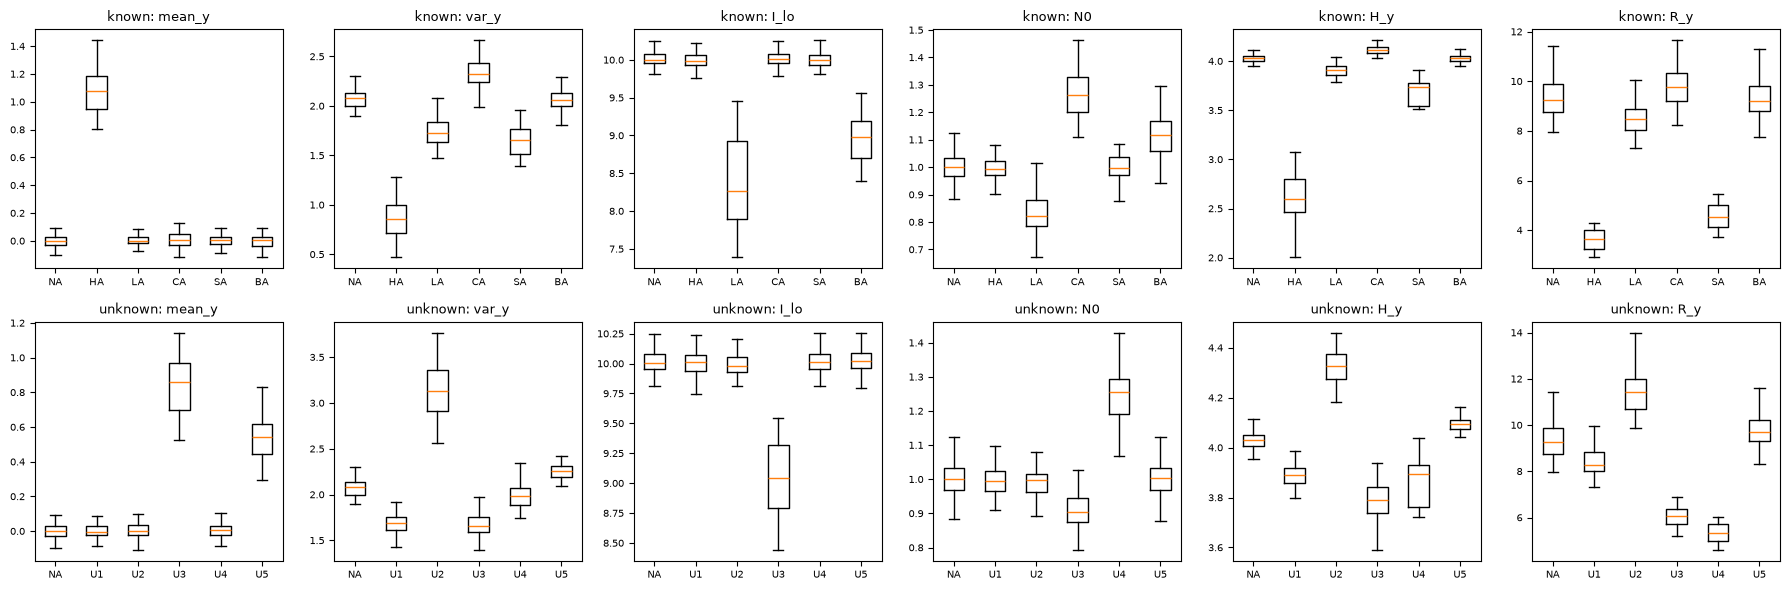

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for r_, nm in enumerate(CLASSES):
    X, y = RAW[nm]
    for c_, fn in enumerate(FEATURES):
        ax = axes[r_, c_]
        ax.boxplot([X[y == k, c_] for k in range(6)], showfliers=False)
        ax.set_xticks(range(1, 7)); ax.set_xticklabels(CLASSES[nm])
        ax.set_title(f"{nm}: {fn}", fontsize=9); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

## 2. Split and standardisation

As in the paper: a 70 : 30 stratified split (420 training blocks, 180 test blocks) and inputs standardised to zero mean and
unit variance. **The scaler is fitted on the training part only** and then applied to the test part, so nothing from the
test set leaks into the model. The standardised value of feature i is used directly as the rotation angle of qubit i.

In [6]:
def prepare(name, seed):
    X, y = make_dataset(name, seed)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    sc = StandardScaler().fit(Xtr)                       # fitted on the training split only
    return sc.transform(Xtr), sc.transform(Xte), ytr, yte

DATA = {(nm, s): prepare(nm, s) for nm in CLASSES for s in DATA_SEEDS}
Xtr, Xte, ytr, yte = DATA[("known", SEED)]
print("train", Xtr.shape, "test", Xte.shape, "| per-class test counts:", np.bincount(yte))

train (420, 6) test (180, 6) | per-class test counts: [30 30 30 30 30 30]


## Dataset Exploration and Visualisation

Before modelling, look at the data itself. The two datasets are generated by our CV-QKD simulator (Section 1), so every
"observation" is one block of 1000 simulated pulses summarised by six numbers. The cell below prints the shape, the feature
names, the original (multiclass attack-type) labels and the class counts, draws the class distribution, and shows a 2-D
scatter of the real observations coloured by their ground-truth label.

For the scatter, a PCA to two components is **fitted on the training split only** (on the standardised features) and applied to
the test split. The left panels show the raw PCA coordinates; the right panels show the same coordinates rescaled to
[0, pi] (min-max fitted on the training split, test values clipped), which is what an angle encoding fed with two PCA
components would see. The models of this notebook do not use PCA: they feed all six standardised features, one per
qubit, so the plot is only a picture of how separable the classes are. Training points are drawn as circles, test points as crosses.

[known] data matrix shape (600, 6) (blocks x features) | features: ['mean_y', 'var_y', 'I_lo', 'N0', 'H_y', 'R_y']
[known] original labels: ['NA', 'HA', 'LA', 'CA', 'SA', 'BA']
[unknown] data matrix shape (600, 6) (blocks x features) | features: ['mean_y', 'var_y', 'I_lo', 'N0', 'H_y', 'R_y']
[unknown] original labels: ['NA', 'U1', 'U2', 'U3', 'U4', 'U5']
[known] class counts (all 600 blocks): {'NA': 100, 'HA': 100, 'LA': 100, 'CA': 100, 'SA': 100, 'BA': 100}
[unknown] class counts (all 600 blocks): {'NA': 100, 'U1': 100, 'U2': 100, 'U3': 100, 'U4': 100, 'U5': 100}
split sizes (70:30): 420 train / 180 test blocks; classes are balanced by construction (100 per class)


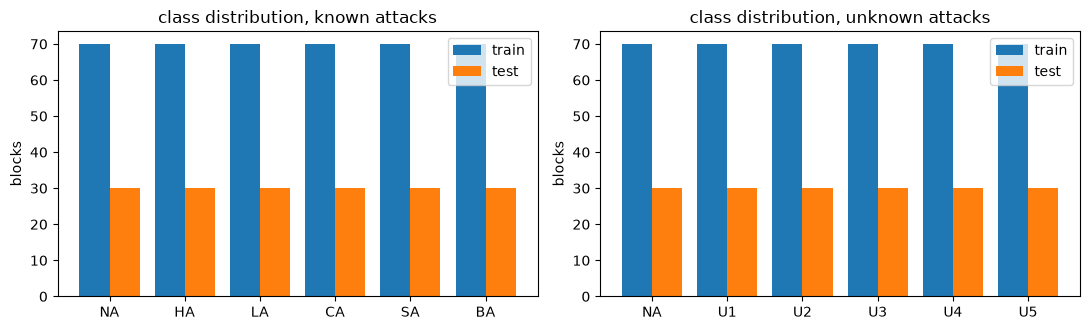

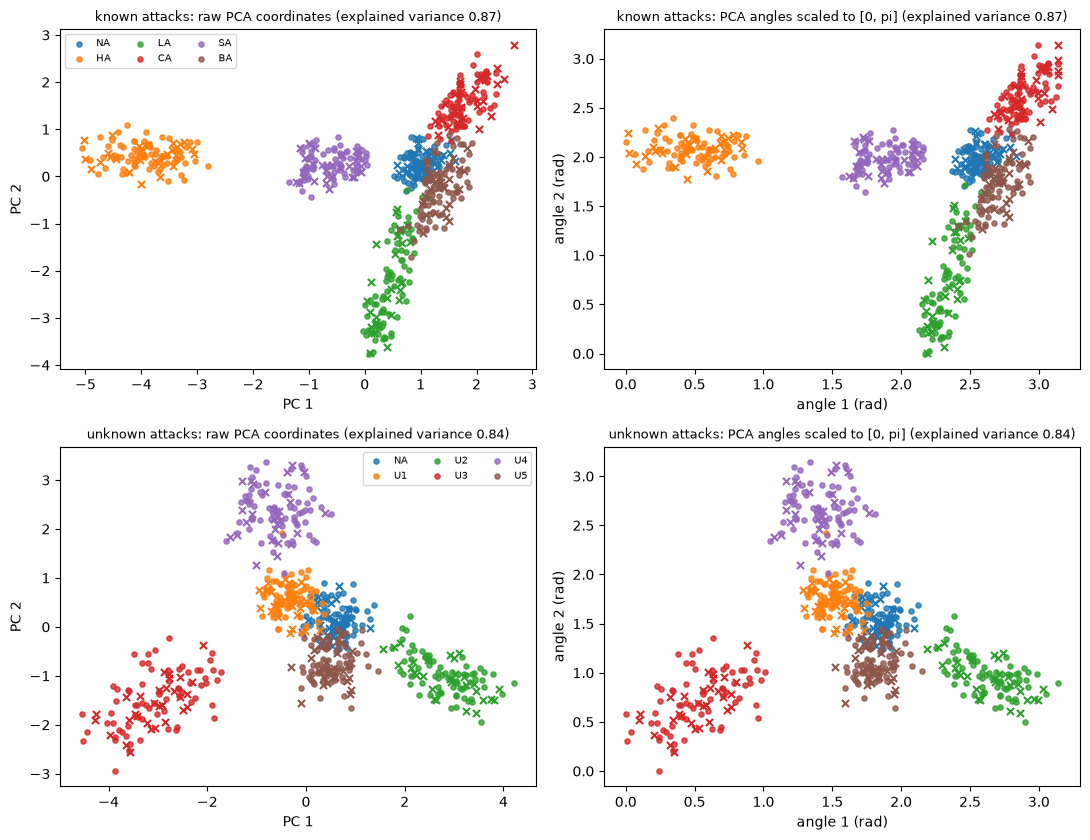

In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

# 1) shape, features, labels, class counts (full simulated dataset of seed SEED, before the split)
for nm in CLASSES:
    X_, y_ = RAW[nm]
    print(f"[{nm}] data matrix shape {X_.shape} (blocks x features) | features: {FEATURES}")
    print(f"[{nm}] original labels: {CLASSES[nm]}")
for nm in CLASSES:
    print(f"[{nm}] class counts (all 600 blocks):", dict(zip(CLASSES[nm], np.bincount(RAW[nm][1], minlength=6).tolist())))
Xtr_s, Xte_s, ytr_s, yte_s = DATA[("known", SEED)]
print("split sizes (70:30):", len(ytr_s), "train /", len(yte_s), "test blocks; classes are balanced by construction (100 per class)")

# 2) class distribution bar chart (train and test counts per class, both datasets)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, nm in zip(axes, CLASSES):
    ytr_, yte_ = DATA[(nm, SEED)][2], DATA[(nm, SEED)][3]
    xs = np.arange(6)
    ax.bar(xs - 0.2, np.bincount(ytr_, minlength=6), 0.4, label="train"); ax.bar(xs + 0.2, np.bincount(yte_, minlength=6), 0.4, label="test")
    ax.set_xticks(xs); ax.set_xticklabels(CLASSES[nm]); ax.set_ylabel("blocks"); ax.set_title(f"class distribution, {nm} attacks"); ax.legend()
plt.tight_layout(); plt.show()

# 3) 2-D scatter of the real observations coloured by ground-truth label (PCA fitted on the training split only)
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
palette = plt.get_cmap("tab10")
for r_, nm in enumerate(CLASSES):
    Xtr_, Xte_, ytr_, yte_ = DATA[(nm, SEED)]
    pca = PCA(n_components=2, random_state=SEED).fit(Xtr_)                 # fitted on the training split only
    Ptr, Pte = pca.transform(Xtr_), pca.transform(Xte_)
    mm = MinMaxScaler((0, np.pi)).fit(Ptr)                                  # [0, pi] angles, fitted on the training split only
    Atr, Ate = mm.transform(Ptr), np.clip(mm.transform(Pte), 0, np.pi)
    for c_, (A, B, ttl) in enumerate([(Ptr, Pte, "raw PCA coordinates"), (Atr, Ate, "PCA angles scaled to [0, pi]")]):
        ax = axes[r_, c_]
        for k, lab in enumerate(CLASSES[nm]):
            ax.scatter(A[ytr_ == k, 0], A[ytr_ == k, 1], s=14, color=palette(k), label=lab, alpha=.8)
            ax.scatter(B[yte_ == k, 0], B[yte_ == k, 1], s=26, color=palette(k), marker="x")
        ax.set_title(f"{nm} attacks: {ttl} (explained variance {pca.explained_variance_ratio_.sum():.2f})", fontsize=9)
        ax.set_xlabel("PC 1" if c_ == 0 else "angle 1 (rad)"); ax.set_ylabel("PC 2" if c_ == 0 else "angle 2 (rad)")
    axes[r_, 0].legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

Reading the picture: in two dimensions the classes already form separate clouds for most attacks, but several overlap (for
example NA, CA and BA in the known data, or NA and U1 in the unknown data), which is why all six features are used. The PCA
captures only part of the variance; the quantum models see the full six-dimensional standardised vector.

## 3. Classical baselines on identical inputs

Before any quantum model, three classical models on exactly the same six standardised features: a random forest, an
RBF-kernel SVM and a linear SVM (one-against-the-rest like the paper's MCSVM). They tell us how hard our simulated task
is: if a classical model already gets 100 %, a perfect quantum score proves little. The classical SVM hyper-parameters are
chosen on the training data only.

In [8]:
def metrics_row(y_true, y_pred):
    out = {"accuracy": accuracy_score(y_true, y_pred)}
    for avg in ["macro", "micro", "weighted"]:
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        out.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_F1": f})
    return out

def classical_baselines(Xtr, ytr, Xte, yte, seed):
    res = {}
    t = time.time(); m = RandomForestClassifier(300, random_state=seed).fit(Xtr, ytr); res["RandomForest"] = (m.predict(Xte), time.time() - t)
    from sklearn.model_selection import GridSearchCV
    t = time.time()
    gs = GridSearchCV(OneVsRestClassifier(SVC(kernel="rbf")), {"estimator__C": [1, 10, 100], "estimator__gamma": [0.05, 0.2, 1.0]},
                      cv=StratifiedKFold(5, shuffle=True, random_state=seed)).fit(Xtr, ytr)
    res["SVC rbf (OvR)"] = (gs.predict(Xte), time.time() - t)
    t = time.time()
    gs = GridSearchCV(OneVsRestClassifier(SVC(kernel="linear")), {"estimator__C": [0.1, 1, 10]},
                      cv=StratifiedKFold(5, shuffle=True, random_state=seed)).fit(Xtr, ytr)
    res["SVC linear (OvR)"] = (gs.predict(Xte), time.time() - t)
    return res

CLASSICAL = {}
for (nm, s), (Xtr_, Xte_, ytr_, yte_) in DATA.items():
    CLASSICAL[(nm, s)] = {k: (accuracy_score(yte_, p), tm) for k, (p, tm) in classical_baselines(Xtr_, ytr_, Xte_, yte_, s).items()}
rows = []
for nm in CLASSES:
    for k in ["RandomForest", "SVC rbf (OvR)", "SVC linear (OvR)"]:
        a = [CLASSICAL[(nm, s)][k][0] for s in DATA_SEEDS]
        rows.append({"dataset": nm, "model": k, "test accuracy mean": np.mean(a), "std": np.std(a), "time/run (s)": np.mean([CLASSICAL[(nm, s)][k][1] for s in DATA_SEEDS])})
display(pd.DataFrame(rows).round(4))

,dataset,model,test accuracy mean,std,time/run (s)
0,known,RandomForest,0.9867,0.0109,1.5547
1,known,SVC rbf (OvR),0.9900,0.0102,1.9616
2,known,SVC linear (OvR),0.9711,0.0065,0.6515
3,unknown,RandomForest,0.9967,0.0027,1.0819
4,unknown,SVC rbf (OvR),0.9900,0.0042,2.4384
5,unknown,SVC linear (OvR),0.9922,0.0027,0.6903


## 4. The six quantum feature maps (Sec. 3.2, Eqs. 2 to 7)

Each standardised block x = (x_0, ..., x_5) is turned into a 6-qubit state.

* **AnRx / AnRy:** every qubit is rotated about X (or Y) by its own feature: cos(x/2)|0> - i sin(x/2)|1> (Eq. 2) or
  cos(x/2)|0> + sin(x/2)|1> (Eq. 3).
* **AnRz:** Hadamard, then a Z-rotation by the feature: (|0> + e^{ix}|1>)/sqrt(2) (Eq. 4).
* **IQP:** Hadamards, Z-rotations, and then a phase exp(-i x_i x_j Z_i Z_j / 2) on pairs of qubits: neighbours in a line
  (IQPl), in a ring (IQPc) or all pairs (IQPf) (Eqs. 5 to 7). We use one repetition.

The *quantum kernel* of two blocks is the squared overlap of their states, k = |<phi(x_i)|phi(x_j)>|^2 (Eq. 9). On
hardware one would run G(x_i), then the inverse G(x_j)^dagger, and read the probability of the all-zero outcome; in the
simulator we take the state vectors and compute the overlaps directly. The cell does both and checks that they agree.

In [9]:
dev_sv = qml.device("default.qubit", wires=N_QUBITS)
VARIANTS = ["AnRx", "AnRy", "AnRz", "IQPl", "IQPc", "IQPf"]
IQP_PAIRS = {"IQPl": [(i, i + 1) for i in range(N_QUBITS - 1)],
             "IQPc": [(i, (i + 1) % N_QUBITS) for i in range(N_QUBITS)],
             "IQPf": [(i, j) for i in range(N_QUBITS) for j in range(i + 1, N_QUBITS)]}

def encode(variant, x):
    # x may carry a leading batch axis; PennyLane broadcasts over it
    W = range(N_QUBITS)
    if variant == "AnRx":
        for q in W: qml.RX(x[..., q], wires=q)
    elif variant == "AnRy":
        for q in W: qml.RY(x[..., q], wires=q)
    else:                                         # AnRz and the IQP maps start with H and RZ
        for q in W: qml.Hadamard(wires=q)
        for q in W: qml.RZ(x[..., q], wires=q)
        if variant != "AnRz":
            for i, j in IQP_PAIRS[variant]:
                qml.IsingZZ(x[..., i] * x[..., j], wires=[i, j])

@qml.qnode(dev_sv)
def state_circuit(variant, x):
    encode(variant, x)
    return qml.state()

def quantum_kernel(variant, XA, XB):
    A, B = np.asarray(state_circuit(variant, np.asarray(XA))), np.asarray(state_circuit(variant, np.asarray(XB)))
    return np.abs(A.conj() @ B.T) ** 2

@qml.qnode(dev_sv)
def hardware_style(variant, xa, xb):               # G(x_a) then G(x_b)^dagger, read P(all zeros)
    encode(variant, xa)
    qml.adjoint(encode)(variant, xb)
    return qml.probs(wires=range(N_QUBITS))

print(qml.draw(lambda x: encode("IQPl", x), decimals=2)(np.round(Xtr[0], 2)))
a, b = Xte[:3], Xtr[:3]
for v in VARIANTS:
    K = quantum_kernel(v, a, b)
    K2 = np.array([[hardware_style(v, a[i], b[j])[0] for j in range(3)] for i in range(3)])
    print(f"{v}: state-vector kernel == 'G then G-dagger' probability:", np.allclose(K, K2))

0: ──H──RZ(-0.52)─╭IsingZZ(0.31)───────────────────────────────────────────────────────────────┤  
1: ──H──RZ(-0.60)─╰IsingZZ(0.31)─╭IsingZZ(-0.36)───────────────────────────────────────────────┤  
2: ──H──RZ(0.60)─────────────────╰IsingZZ(-0.36)─╭IsingZZ(-0.17)───────────────────────────────┤  
3: ──H──RZ(-0.29)────────────────────────────────╰IsingZZ(-0.17)─╭IsingZZ(0.11)────────────────┤  
4: ──H──RZ(-0.39)────────────────────────────────────────────────╰IsingZZ(0.11)─╭IsingZZ(0.52)─┤  
5: ──H──RZ(-1.34)───────────────────────────────────────────────────────────────╰IsingZZ(0.52)─┤  


AnRx: state-vector kernel == 'G then G-dagger' probability: True
AnRy: state-vector kernel == 'G then G-dagger' probability: True


AnRz: state-vector kernel == 'G then G-dagger' probability: True
IQPl: state-vector kernel == 'G then G-dagger' probability: True


IQPc: state-vector kernel == 'G then G-dagger' probability: True
IQPf: state-vector kernel == 'G then G-dagger' probability: True


**Kernel equivalence and what the AnR kernel really is.** The paper states that the AnRx, AnRy and AnRz kernels are
identical. The next cell confirms it numerically, and also shows that this kernel has a closed form with no quantum
ingredient: for angle encoding there is no entanglement, so k(x, x') = prod_q cos^2((x_q - x'_q)/2). A classical computer
evaluates this in microseconds; we check that a plain classical SVM given that formula reproduces the "quantum" kernel.
We come back to this in the critical reading.

In [10]:
Ka = {v: quantum_kernel(v, Xte[:25], Xtr[:25]) for v in VARIANTS}
closed = np.prod(np.cos((Xte[:25, None, :] - Xtr[None, :25, :]) / 2) ** 2, axis=2)
print("max |K_AnRx - K_AnRy| =", np.abs(Ka["AnRx"] - Ka["AnRy"]).max(), "| max |K_AnRx - K_AnRz| =", np.abs(Ka["AnRx"] - Ka["AnRz"]).max())
print("max |K_AnRx - closed form prod cos^2| =", np.abs(Ka["AnRx"] - closed).max())
print("AnRx vs IQPl differ:", np.abs(Ka["AnRx"] - Ka["IQPl"]).max() > 1e-3)

max |K_AnRx - K_AnRy| = 1.1102230246251565e-15 | max |K_AnRx - K_AnRz| = 2.9976021664879227e-15
max |K_AnRx - closed form prod cos^2| = 1.3322676295501878e-15
AnRx vs IQPl differ: True


## 5. QSVM: quantum kernel + one-against-the-rest SVM (Sec. 4.2.1)

For each class s a binary SVM is trained on the precomputed kernel (Eq. 10), giving a score function (Eq. 11); the predicted
class is the one with the largest score (Eq. 12). The penalty C is not given; we pick it from a small grid by five-fold
cross-validation **on the training kernel only**.

**Fig. 5 (five-fold cross-validation).** In every fold the standardiser is refitted on the four training folds, the kernel
is recomputed, C is chosen inside the training folds, and the fifth fold is scored. **Fig. 6 (70 : 30).** Confusion matrices
of the AnR-type QSVM.

In [11]:
def fit_predict_kernel_svm(Ktr, ytr, Kte, seed=SEED, c_grid=C_GRID):
    # one-against-the-rest SVM on a precomputed kernel; C picked by 5-fold CV on the training kernel only
    if len(c_grid) == 1:
        bestc = c_grid[0]
    else:
        skf = StratifiedKFold(5, shuffle=True, random_state=seed)
        best, bestc = -1, c_grid[0]
        for C in c_grid:
            accs = []
            for tr, va in skf.split(Ktr, ytr):
                m = OneVsRestClassifier(SVC(kernel="precomputed", C=C)).fit(Ktr[np.ix_(tr, tr)], ytr[tr])
                accs.append((m.predict(Ktr[np.ix_(va, tr)]) == ytr[va]).mean())
            if np.mean(accs) > best + 1e-12:
                best, bestc = np.mean(accs), C
    m = OneVsRestClassifier(SVC(kernel="precomputed", C=bestc)).fit(Ktr, ytr)
    return m.predict(Kte), bestc

# ---- 70:30 split, all six variants, all data seeds
QSVM = {}                                # (dataset, seed, variant) -> dict(pred, C, time)
for (nm, s), (Xtr_, Xte_, ytr_, yte_) in DATA.items():
    for v in VARIANTS:
        t = time.time()
        Ktr, Kte = quantum_kernel(v, Xtr_, Xtr_), quantum_kernel(v, Xte_, Xtr_)
        pred, C = fit_predict_kernel_svm(Ktr, ytr_, Kte, seed=s)
        QSVM[(nm, s, v)] = dict(pred=pred, C=C, time=time.time() - t, acc=accuracy_score(yte_, pred))
rows = []
for nm in CLASSES:
    for v in VARIANTS:
        a = [QSVM[(nm, s, v)]["acc"] for s in DATA_SEEDS]
        rows.append({"dataset": nm, "model": f"{v}-QSVM", "test acc mean": np.mean(a), "std": np.std(a), "min": np.min(a), "chosen C (seed 42)": QSVM[(nm, SEED, v)]["C"],
                     "time/run (s)": np.mean([QSVM[(nm, s, v)]["time"] for s in DATA_SEEDS])})
display(pd.DataFrame(rows).round(4))

,dataset,model,test acc mean,std,min,chosen C (seed 42),time/run (s)
0,known,AnRx-QSVM,0.9889,0.0105,0.9722,1.0,1.3742
1,known,AnRy-QSVM,0.9889,0.0105,0.9722,1.0,1.4216
2,known,AnRz-QSVM,0.9889,0.0105,0.9722,1.0,1.5255
3,known,IQPl-QSVM,0.9889,0.0122,0.9667,1.0,1.3785
4,known,IQPc-QSVM,0.9900,0.0102,0.9722,1.0,1.2183
5,known,IQPf-QSVM,0.9889,0.0105,0.9722,0.1,1.9279
6,unknown,AnRx-QSVM,0.9933,0.0042,0.9889,1.0,1.2641
7,unknown,AnRy-QSVM,0.9933,0.0042,0.9889,1.0,1.1254
8,unknown,AnRz-QSVM,0.9933,0.0042,0.9889,1.0,1.1012
9,unknown,IQPl-QSVM,0.9889,0.0079,0.9778,1.0,1.1767


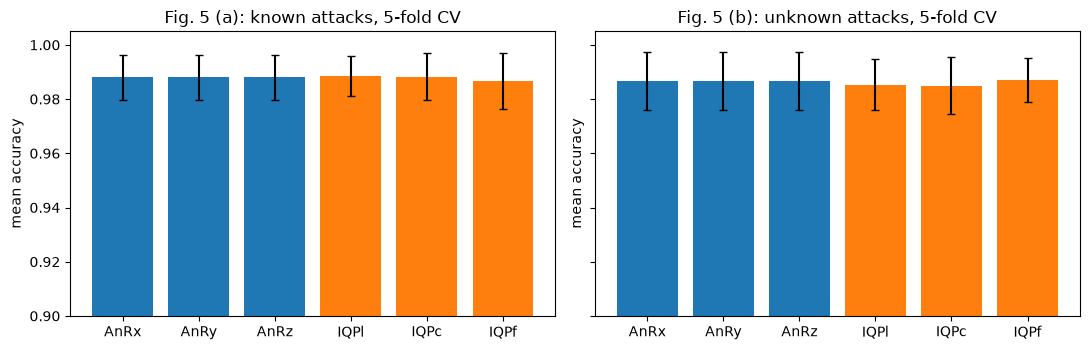

,known,unknown
AnRx,0.9880 +- 0.0082,0.9867 +- 0.0108
AnRy,0.9880 +- 0.0082,0.9867 +- 0.0108
AnRz,0.9880 +- 0.0082,0.9867 +- 0.0108
IQPl,0.9887 +- 0.0074,0.9853 +- 0.0095
IQPc,0.9883 +- 0.0088,0.9850 +- 0.0105
IQPf,0.9867 +- 0.0103,0.9870 +- 0.0082


In [12]:
# ---- Fig. 5: five-fold cross-validation mean accuracy of the six QSVM variants
FIG5 = {}
for nm in CLASSES:
    for v in VARIANTS:
        accs = []
        for s in DATA_SEEDS:
            X, y = make_dataset(nm, s)
            for tr, te in StratifiedKFold(CV_FOLDS, shuffle=True, random_state=s).split(X, y):
                sc = StandardScaler().fit(X[tr])
                A, B = sc.transform(X[tr]), sc.transform(X[te])
                pred, _ = fit_predict_kernel_svm(quantum_kernel(v, A, A), y[tr], quantum_kernel(v, B, A), seed=s)
                accs.append(accuracy_score(y[te], pred))
        FIG5[(nm, v)] = (np.mean(accs), np.std(accs))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, nm in zip(axes, CLASSES):
    m = [FIG5[(nm, v)][0] for v in VARIANTS]; sd = [FIG5[(nm, v)][1] for v in VARIANTS]
    ax.bar(VARIANTS, m, yerr=sd, color=["tab:blue"] * 3 + ["tab:orange"] * 3, capsize=3)
    ax.set_ylim(0.9 if min(m) > 0.9 else 0.5, 1.005); ax.set_title(f"Fig. 5 ({'a' if nm == 'known' else 'b'}): {nm} attacks, 5-fold CV"); ax.set_ylabel("mean accuracy")
plt.tight_layout(); plt.show()
display(pd.DataFrame({nm: {v: f"{FIG5[(nm, v)][0]:.4f} +- {FIG5[(nm, v)][1]:.4f}" for v in VARIANTS} for nm in CLASSES}))

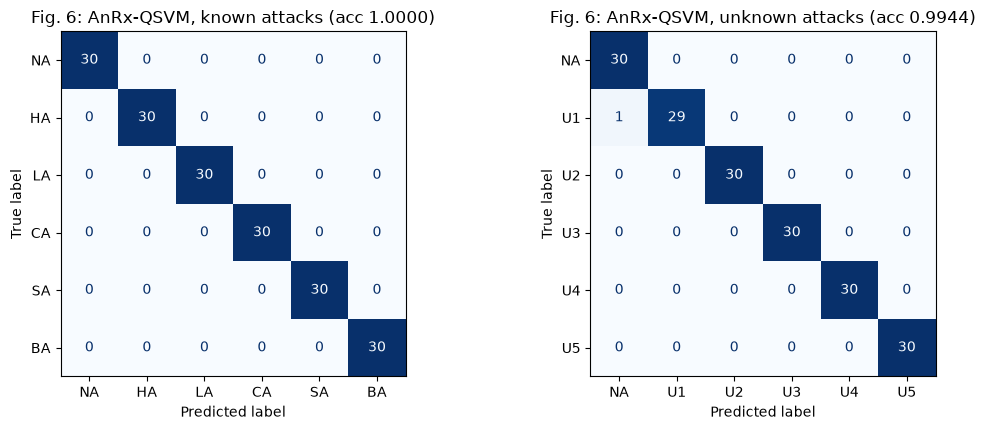

AnRx / AnRy / AnRz give the same predictions: True


In [13]:
# ---- Fig. 6: confusion matrices of the AnR-type QSVM (70:30, seed 42); attack classes in rows
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, nm in zip(axes, CLASSES):
    yte_ = DATA[(nm, SEED)][3]
    ConfusionMatrixDisplay(confusion_matrix(yte_, QSVM[(nm, SEED, "AnRx")]["pred"], labels=range(6)), display_labels=CLASSES[nm]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Fig. 6: AnRx-QSVM, {nm} attacks (acc {QSVM[(nm, SEED, 'AnRx')]['acc']:.4f})")
plt.tight_layout(); plt.show()
print("AnRx / AnRy / AnRz give the same predictions:", all(np.array_equal(QSVM[(nm, SEED, "AnRx")]["pred"], QSVM[(nm, SEED, "AnRz")]["pred"]) for nm in CLASSES))

## 6. QNN: variational circuit with Pauli-Z read-out (Sec. 4.2.2)

After the feature map, L_d = 6 layers of *general* single-qubit rotations (the matrix of Eq. 14 is PennyLane's `Rot`) and
CNOT gates: in layer l qubit q controls qubit (q + l) mod 6, which is what `StronglyEntanglingLayers` with ranges 1, 2, 3, 4, 5
does (the paper has l between 1 and n - 1; our sixth layer repeats range 1). The depth L_d is not given in the paper; in a pilot
run on the unknown-attack data a 4-layer AnRx-QNN stayed near 85 % test accuracy and a 6-layer one reached about 97 %, so 6 is used. The six Pauli-Z expectation values <Z_0..Z_5> are the logits of the six classes; the loss is the softmax
cross-entropy of Eq. 17 (the logits stay in [-1, 1], which is why the paper's loss never gets near zero), minimised with Adam.

**Training protocol.** Learning-rate scheduler: halve the rate after 5 epochs without validation-loss improvement (floor 1e-6).
Early stopping: after 10 epochs without improvement. **Difference from the paper:** the paper stops on the *testing*
accuracy; we monitor a validation part (15 %) of the training data and finally report the test accuracy of the best
validation epoch, so the test set is never used to choose anything. The testing-accuracy curve is still recorded for the
Fig. 7 and Fig. 8 plots. The gradient is computed by back-propagation through the simulator (identical to the parameter-shift
gradient for exact expectation values, much faster).

In [14]:
def make_qnn(variant, n_layers=QNN_LAYERS):
    dev = qml.device("default.qubit", wires=N_QUBITS)
    ranges = [(l % (N_QUBITS - 1)) + 1 for l in range(n_layers)]          # CNOT target = (q + l) mod n
    @qml.qnode(dev, interface="autograd", diff_method="backprop")
    def circuit(x, w):
        encode(variant, x)
        qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS), ranges=ranges)
        return [qml.expval(qml.PauliZ(q)) for q in range(N_QUBITS)]
    return lambda x, w: pnp.stack(circuit(x, w), axis=-1)

def cross_entropy(logits, y_onehot):                                       # Eq. 17, averaged over the batch
    zmax = pnp.max(logits, axis=1)
    lse = pnp.log(pnp.sum(pnp.exp(logits - zmax[:, None]), axis=1))
    return pnp.mean(zmax + lse - pnp.sum(logits * y_onehot, axis=1))

def train_qnn(variant, Xtr, ytr, Xte, yte, seed, epochs=QNN_EPOCHS, batch=QNN_BATCH, lr=QNN_LR):
    r = np.random.default_rng(seed)
    Xa, Xv, ya, yv = train_test_split(Xtr, ytr, test_size=VAL_FRACTION, stratify=ytr, random_state=seed)
    logits = make_qnn(variant)
    w = pnp.array(r.uniform(0, 2 * np.pi, (QNN_LAYERS, N_QUBITS, 3)), requires_grad=True)    # CHOICE: uniform initial angles
    onehot = lambda y: np.eye(N_QUBITS)[y]
    opt = qml.AdamOptimizer(stepsize=lr)
    hist = {k: [] for k in ["loss", "train_acc", "val_acc", "val_loss", "test_acc"]}
    best_w, best_ep, bad, sbad, best_vl = None, 0, 0, 0, np.inf          # CHOICE: select / stop on the validation LOSS (stable on 63 blocks)
    for ep in range(epochs):
        order = r.permutation(len(ya))
        for s0 in range(0, len(ya), batch):
            idx = order[s0:s0 + batch]
            xb, yb = pnp.array(Xa[idx], requires_grad=False), onehot(ya[idx])
            w = opt.step(lambda w_: cross_entropy(logits(xb, w_), yb), w)
        lg_a, lg_v, lg_t = (np.asarray(logits(pnp.array(X_, requires_grad=False), w)) for X_ in (Xa, Xv, Xte))
        hist["loss"].append(float(cross_entropy(pnp.array(lg_a), onehot(ya)))); hist["val_loss"].append(float(cross_entropy(pnp.array(lg_v), onehot(yv))))
        hist["train_acc"].append(float((lg_a.argmax(1) == ya).mean())); hist["val_acc"].append(float((lg_v.argmax(1) == yv).mean()))
        hist["test_acc"].append(float((lg_t.argmax(1) == yte).mean()))
        if hist["val_loss"][-1] < best_vl - 1e-6: best_vl, best_w, best_ep, bad, sbad = hist["val_loss"][-1], np.array(w), ep, 0, 0
        else:
            bad += 1; sbad += 1
            if sbad >= SCHED_PATIENCE: opt.stepsize, sbad = max(opt.stepsize * SCHED_FACTOR, LR_MIN), 0
        if bad >= QNN_PATIENCE: break
    pred = np.asarray(logits(pnp.array(Xte, requires_grad=False), pnp.array(best_w))).argmax(1)
    return pred, hist, best_ep

QNN = {}
for nm in CLASSES:
    Xtr_, Xte_, ytr_, yte_ = DATA[(nm, SEED)]
    for v in QNN_VARIANTS:
        t = time.time()
        pred, hist, best_ep = train_qnn(v, Xtr_, ytr_, Xte_, yte_, SEED)
        QNN[(nm, v)] = dict(pred=pred, hist=hist, best_ep=best_ep, acc=accuracy_score(yte_, pred), time=time.time() - t)
        print(f"{nm:8s} {v}-QNN: test acc {QNN[(nm, v)]['acc']:.4f} (best validation epoch {best_ep + 1}/{len(hist['loss'])}), {QNN[(nm, v)]['time']:.0f} s")

known    AnRx-QNN: test acc 0.9778 (best validation epoch 45/45), 423 s


known    AnRy-QNN: test acc 0.9833 (best validation epoch 45/45), 659 s


known    AnRz-QNN: test acc 0.9389 (best validation epoch 45/45), 572 s


known    IQPl-QNN: test acc 0.9222 (best validation epoch 45/45), 407 s


known    IQPc-QNN: test acc 0.9222 (best validation epoch 45/45), 493 s


...

unknown  AnRy-QNN: test acc 0.9556 (best validation epoch 45/45), 484 s


unknown  AnRz-QNN: test acc 0.9500 (best validation epoch 45/45), 398 s


unknown  IQPl-QNN: test acc 0.7333 (best validation epoch 45/45), 439 s


unknown  IQPc-QNN: test acc 0.8611 (best validation epoch 45/45), 443 s


unknown  IQPf-QNN: test acc 0.8278 (best validation epoch 45/45), 417 s


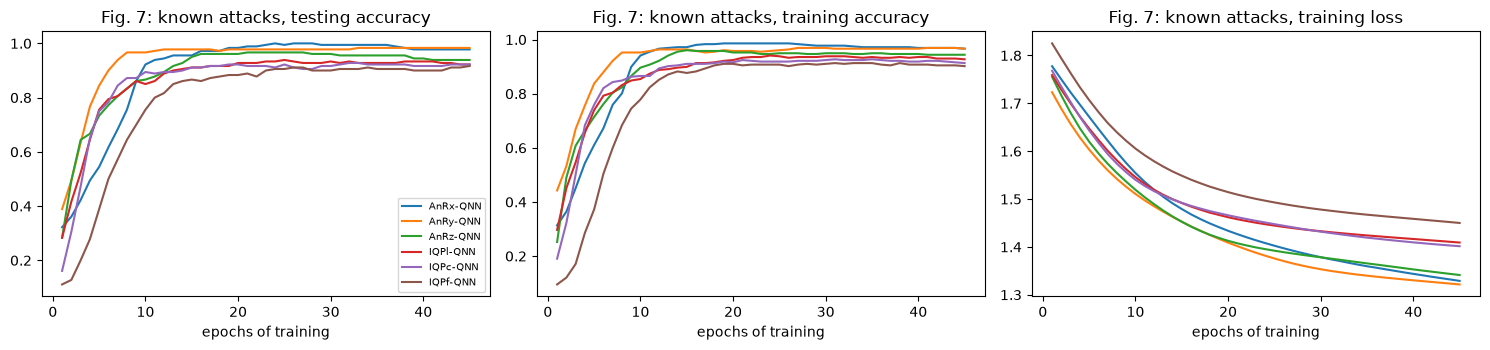

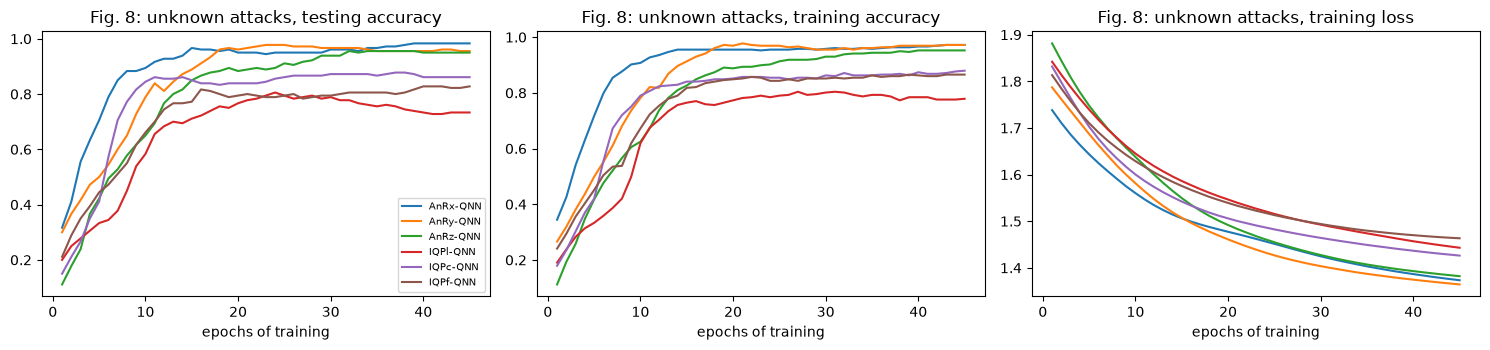

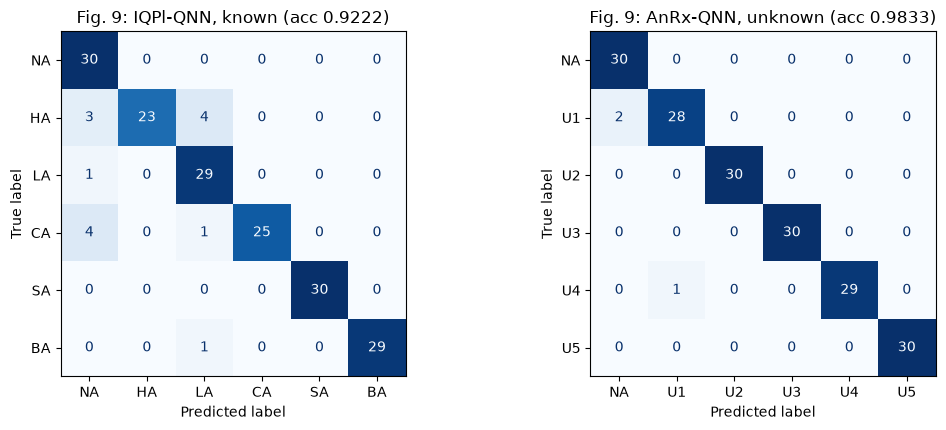

,dataset,model,test accuracy,epochs run,time (s)
0,known,AnRx-QNN,0.9778,45,423.0902
1,known,AnRy-QNN,0.9833,45,659.0201
2,known,AnRz-QNN,0.9389,45,571.6295
3,known,IQPl-QNN,0.9222,45,406.5420
4,known,IQPc-QNN,0.9222,45,492.6923
5,known,IQPf-QNN,0.9167,45,492.5993
6,unknown,AnRx-QNN,0.9833,45,527.9983
7,unknown,AnRy-QNN,0.9556,45,484.2073
8,unknown,AnRz-QNN,0.9500,45,398.0620
9,unknown,IQPl-QNN,0.7333,45,439.2576


In [15]:
# ---- Figs. 7 and 8: accuracy and loss versus epoch
for nm, fig_no in zip(CLASSES, (7, 8)):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    for v in QNN_VARIANTS:
        h = QNN[(nm, v)]["hist"]; ep = np.arange(1, len(h["loss"]) + 1)
        axes[0].plot(ep, h["test_acc"], label=f"{v}-QNN"); axes[1].plot(ep, h["train_acc"], label=f"{v}-QNN"); axes[2].plot(ep, h["loss"], label=f"{v}-QNN")
    for ax, t_ in zip(axes, ["testing accuracy", "training accuracy", "training loss"]):
        ax.set_xlabel("epochs of training"); ax.set_title(f"Fig. {fig_no}: {nm} attacks, {t_}")
    axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

# ---- Fig. 9: confusion matrices of the paper's best QNNs (IQPl on known, AnRx on unknown), if trained
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (nm, v) in zip(axes, [("known", "IQPl"), ("unknown", "AnRx")]):
    yte_ = DATA[(nm, SEED)][3]
    ConfusionMatrixDisplay(confusion_matrix(yte_, QNN[(nm, v)]["pred"], labels=range(6)), display_labels=CLASSES[nm]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Fig. 9: {v}-QNN, {nm} (acc {QNN[(nm, v)]['acc']:.4f})")
plt.tight_layout(); plt.show()
display(pd.DataFrame([{"dataset": nm, "model": f"{v}-QNN", "test accuracy": QNN[(nm, v)]["acc"], "epochs run": len(QNN[(nm, v)]["hist"]["loss"]), "time (s)": QNN[(nm, v)]["time"]}
                      for nm in CLASSES for v in QNN_VARIANTS]).round(4))

## 7. Noise robustness (Sec. 6, Table 1, Tables 2 to 5)

**The four noise channels** act on one qubit: bit flip (probability delta_BFC), amplitude damping (delta_ADC: |1> decays to |0>),
phase damping (delta_PDC: loss of coherence without energy loss) and depolarizing noise (delta_DPC: X, Y or Z error with
total probability delta_DPC). They are written as Kraus operators (Eqs. 20 to 24). The paper derives their strengths from
hardware numbers: delta_ADC = 1 - exp(-t/T1), delta_PDC = 1 - exp(t/T1 - 2t/T2) with gate time t = 100 ns, delta_DPC = 1.5 x
(single-qubit gate error), delta_BFC = readout error. The three artificial backends of Table 1 are copied below; the
cell recomputes delta_ADC, delta_PDC, delta_DPC from T1, T2 and the gate error to confirm we read the table correctly.

**Our noisy kernel.** The AnR circuits contain only single-qubit gates, so the circuit "G(x_i), G(x_j)^dagger, measure all
zero" is a product over qubits and the all-zero probability is the product of six single-qubit probabilities. We compute
each of them exactly with 2 x 2 density matrices. Noise is placed as described in the table at the top (D, A, P after every gate
but the last; D then B after the last gate). The cell compares the result with PennyLane's `default.mixed` simulator running
the full six-qubit noisy circuit, for several pairs of blocks.

In [16]:
I2 = np.eye(2, dtype=complex); X_ = np.array([[0, 1], [1, 0]], complex); Y_ = np.array([[0, -1j], [1j, 0]]); Z_ = np.diag([1, -1]).astype(complex)
H_ = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2)
def _rot(P, a):  a = np.asarray(a, float)[..., None, None]; return np.cos(a / 2) * I2 - 1j * np.sin(a / 2) * P
def _rz(a):
    a = np.asarray(a, float); out = np.zeros(a.shape + (2, 2), complex); out[..., 0, 0] = np.exp(-1j * a / 2); out[..., 1, 1] = np.exp(1j * a / 2); return out
def _unitary(rho, U): return U @ rho @ np.conj(np.swapaxes(U, -1, -2))
def _kraus(rho, Ks):  return sum(K @ rho @ K.conj().T for K in Ks)
def _adj_kraus(O, Ks): return sum(K.conj().T @ O @ K for K in Ks)                      # Heisenberg picture of a channel
def _adj_unitary(O, U): return np.conj(np.swapaxes(U, -1, -2)) @ O @ U
def kraus_depol(p):   return [np.sqrt(1 - p) * I2, np.sqrt(p / 3) * X_, np.sqrt(p / 3) * Y_, np.sqrt(p / 3) * Z_]          # Eq. 24
def kraus_ad(g):      return [np.array([[1, 0], [0, np.sqrt(1 - g)]], complex), np.array([[0, np.sqrt(g)], [0, 0]], complex)]  # Eq. 21
def kraus_pd(g):      return [np.array([[1, 0], [0, np.sqrt(1 - g)]], complex), np.array([[0, 0], [0, np.sqrt(g)]], complex)]  # Eq. 22

# Table 1 (the three "Ours" rows): T1, T2 in microseconds, single-qubit gate error eps1, readout error eps_m
TABLE1 = {"LNRM": dict(T1=10.0, T2=10.0, eps1=6.0e-3, epsm=6.75e-2), "MNSTM": dict(T1=1.0, T2=1.0, eps1=7.6e-2, epsm=9.25e-2), "HNAM": dict(T1=1.0, T2=1.0, eps1=1.5e-1, epsm=1.5e-1)}
GATE_T = 0.1   # microseconds (100 ns)
NOISE = {}
for k, d in TABLE1.items():
    NOISE[k] = dict(bfc=d["epsm"], adc=1 - np.exp(-GATE_T / d["T1"]), pdc=1 - np.exp(GATE_T / d["T1"] - 2 * GATE_T / d["T2"]), dpc=1.5 * d["eps1"])
print(pd.DataFrame(NOISE).T.round(5).rename(columns=str.upper))
print("paper Table 1: LNRM  delta_ADC 9.95e-3, PDC 9.95e-3, DPC 9.00e-3 | MNSTM/HNAM  delta_ADC 9.52e-2, PDC 9.52e-2, DPC 1.14e-1 / 2.25e-1")

def noisy_kernel(variant, XA, XB, nb):
    # K[i, j] = prod_q P(0 | G(xA_i[q]) then G^dagger(xB_j[q]) with noise)
    # Speed trick: the state after the gates that depend on x_i only (shape N) is combined with the Heisenberg-picture
    # operator of everything that comes after, which depends on x_j only (shape M): P(0) = Tr(E_j sigma_i).
    XA, XB = np.asarray(XA), np.asarray(XB)
    K = np.ones((len(XA), len(XB)))
    mid  = lambda r: _kraus(_kraus(_kraus(r, kraus_depol(nb["dpc"])), kraus_ad(nb["adc"])), kraus_pd(nb["pdc"]))      # D, then A, then P
    amid = lambda O: _adj_kraus(_adj_kraus(_adj_kraus(O, kraus_pd(nb["pdc"])), kraus_ad(nb["adc"])), kraus_depol(nb["dpc"]))   # adjoint of mid
    P0 = np.zeros((2, 2), complex); P0[0, 0] = 1
    O_end = _adj_kraus(P0, kraus_depol(nb["dpc"]))                                                                # last D before the read-out
    for q in range(N_QUBITS):
        a, b = XA[:, q], XB[:, q]
        rho0 = np.zeros((len(a), 2, 2), complex); rho0[:, 0, 0] = 1
        if variant in ("AnRx", "AnRy"):                       # gates: R(a), R(-b)
            P = X_ if variant == "AnRx" else Y_
            sigma = mid(_unitary(rho0, _rot(P, a)))
            U = _rot(P, -b); E = _adj_unitary(O_end, U)
        else:                                                 # AnRz: H, RZ(a), RZ(-b), H
            sigma = mid(_unitary(mid(_unitary(rho0, H_)), _rz(a)))
            O3 = amid(_adj_unitary(O_end, H_))
            E = _adj_unitary(O3, _rz(-b))
        p0 = np.einsum("mxy,nyx->nm", E, sigma).real
        K *= (1 - nb["bfc"]) * p0 + nb["bfc"] * (1 - p0)      # B: readout bit flip
    return K

def noisy_kernel_pennylane(variant, xa, xb, nb):                       # the same circuit on the full 6-qubit mixed-state simulator
    dev = qml.device("default.mixed", wires=N_QUBITS)
    def noise_mid(q):
        qml.DepolarizingChannel(nb["dpc"], wires=q); qml.AmplitudeDamping(nb["adc"], wires=q); qml.PhaseDamping(nb["pdc"], wires=q)
    @qml.qnode(dev)
    def circ():
        for q in range(N_QUBITS):
            if variant in ("AnRx", "AnRy"):
                G = qml.RX if variant == "AnRx" else qml.RY
                G(xa[q], wires=q); noise_mid(q); G(-xb[q], wires=q)
            else:
                qml.Hadamard(wires=q); noise_mid(q); qml.RZ(xa[q], wires=q); noise_mid(q); qml.RZ(-xb[q], wires=q); noise_mid(q); qml.Hadamard(wires=q)
            qml.DepolarizingChannel(nb["dpc"], wires=q); qml.BitFlip(nb["bfc"], wires=q)
        return qml.probs(wires=range(N_QUBITS))
    return float(circ()[0])

errs = []
for v in ["AnRx", "AnRy", "AnRz"]:
    for k, nb in NOISE.items():
        Kn = noisy_kernel(v, Xte[:2], Xtr[:2], nb)
        errs.append(max(abs(Kn[i, j] - noisy_kernel_pennylane(v, Xte[i], Xtr[j], nb)) for i in range(2) for j in range(2)))
print(f"largest |our noisy kernel - PennyLane default.mixed| over 3 variants x 3 backends x 4 pairs: {max(errs):.2e}")
assert max(errs) < 1e-8
print("mean diagonal of the noisy AnRx kernel (1.0 without noise):", {k: round(float(np.diag(noisy_kernel('AnRx', Xtr[:50], Xtr[:50], nb)).mean()), 3) for k, nb in NOISE.items()})

          BFC      ADC      PDC    DPC
LNRM   0.0675  0.00995  0.00995  0.009
MNSTM  0.0925  0.09516  0.09516  0.114
HNAM   0.1500  0.09516  0.09516  0.225
paper Table 1: LNRM  delta_ADC 9.95e-3, PDC 9.95e-3, DPC 9.00e-3 | MNSTM/HNAM  delta_ADC 9.52e-2, PDC 9.52e-2, DPC 1.14e-1 / 2.25e-1


largest |our noisy kernel - PennyLane default.mixed| over 3 variants x 3 backends x 4 pairs: 3.99e-13
mean diagonal of the noisy AnRx kernel (1.0 without noise): {'LNRM': 0.608, 'MNSTM': 0.233, 'HNAM': 0.09}


**Training and testing under noise.** The kernel matrices (training x training and test x training) are computed with the
noisy circuit, the SVM is trained on the noisy training kernel and scored on the noisy test kernel, exactly as the paper's
simulation does. The headline numbers re-tune C on the noisy training kernel (a noisier kernel has smaller values, so it
needs a larger C; this is legitimate because the tuning uses training data only). Because the paper does not say how C was
chosen, a second run with a **fixed C = 1** shows how much of the noise effect is only a scale effect.

In [17]:
NOISY = {}      # (dataset, variant, backend, 'tuned'|'C1') -> dict(test_acc, train_acc, pred)
t = time.time()
for nm in CLASSES:
    Xtr_, Xte_, ytr_, yte_ = DATA[(nm, SEED)]
    for v in ["AnRx", "AnRy", "AnRz"]:
        for bk, nb in NOISE.items():
            Ktr, Kte = noisy_kernel(v, Xtr_, Xtr_, nb), noisy_kernel(v, Xte_, Xtr_, nb)
            for mode, grid in [("tuned", C_GRID), ("C1", [1])]:
                pred, C = fit_predict_kernel_svm(Ktr, ytr_, Kte, seed=SEED, c_grid=grid)
                m = OneVsRestClassifier(SVC(kernel="precomputed", C=C)).fit(Ktr, ytr_)
                NOISY[(nm, v, bk, mode)] = dict(test_acc=accuracy_score(yte_, pred), train_acc=accuracy_score(ytr_, m.predict(Ktr)), pred=pred, C=C)
print(f"noisy QSVM runs finished in {time.time() - t:.0f} s")

PAPER_T2 = {  # Table 2 (known) and Table 3 (unknown): (test, train) for AnRx, AnRy, AnRz
 ("known", "LNRM"):  [(1.0000, 1.0000), (0.9944, 0.9976), (1.0000, 0.9976)], ("known", "MNSTM"): [(0.9889, 0.9881), (0.9944, 0.9929), (0.8778, 0.8500)],
 ("known", "HNAM"):  [(0.9111, 0.8857), (0.8722, 0.8714), (0.4000, 0.3738)],
 ("unknown", "LNRM"): [(1.0, 1.0), (1.0, 1.0), (1.0, 1.0)], ("unknown", "MNSTM"): [(1.0, 1.0), (1.0, 1.0), (1.0, 1.0)],
 ("unknown", "HNAM"): [(1.0, 1.0), (1.0, 1.0), (0.3667, 0.3476)]}
rows = []
for (nm, bk), vals in PAPER_T2.items():
    for v, (pt, ptr) in zip(["AnRx", "AnRy", "AnRz"], vals):
        r_ = NOISY[(nm, v, bk, "tuned")]
        rows.append({"dataset": nm, "backend": bk, "model": f"{v}-QSVM", "paper test": pt, "ours test (C tuned)": r_["test_acc"], "ours test (C=1)": NOISY[(nm, v, bk, "C1")]["test_acc"],
                     "paper train": ptr, "ours train (C tuned)": r_["train_acc"], "chosen C": r_["C"]})
T23 = pd.DataFrame(rows)
T23["gap (tuned - paper)"] = T23["ours test (C tuned)"] - T23["paper test"]
T23["verdict"] = np.where(T23["gap (tuned - paper)"].abs() <= 0.02, "reproduced", np.where(T23["gap (tuned - paper)"] < 0, "not reached", "exceeded"))
display(T23.round(4))
print(T23.groupby("dataset")["verdict"].value_counts().unstack(fill_value=0))

noisy QSVM runs finished in 26 s


,dataset,backend,model,paper test,ours test (C tuned),ours test (C=1),paper train,ours train (C tuned),chosen C,gap (tuned - paper),verdict
0,known,LNRM,AnRx-QSVM,1.0000,1.0000,1.0000,1.0000,0.9905,1,0.0000,reproduced
1,known,LNRM,AnRy-QSVM,0.9944,1.0000,1.0000,0.9976,0.9905,1,0.0056,reproduced
2,known,LNRM,AnRz-QSVM,1.0000,1.0000,1.0000,0.9976,0.9905,1,0.0000,reproduced
3,known,MNSTM,AnRx-QSVM,0.9889,0.9944,0.9944,0.9881,0.9952,100,0.0055,reproduced
4,known,MNSTM,AnRy-QSVM,0.9944,0.9944,0.9944,0.9929,0.9952,100,0.0000,reproduced
5,known,MNSTM,AnRz-QSVM,0.8778,1.0000,0.9944,0.8500,0.9905,10,0.1222,exceeded
6,known,HNAM,AnRx-QSVM,0.9111,0.9833,0.9944,0.8857,0.9976,1000,0.0722,exceeded
7,known,HNAM,AnRy-QSVM,0.8722,0.9833,0.9944,0.8714,0.9976,1000,0.1111,exceeded
8,known,HNAM,AnRz-QSVM,0.4000,1.0000,0.9778,0.3738,0.9881,100,0.6000,exceeded
9,unknown,LNRM,AnRx-QSVM,1.0000,1.0000,0.9944,1.0000,0.9929,10,0.0000,reproduced


verdict  exceeded  not reached  reproduced
dataset                                   
known           4            0           5
unknown         1            2           6


In [18]:
# ---- Tables 4 and 5: macro / micro / weighted precision, recall, F1 on the test set (C tuned)
for nm, tn in zip(CLASSES, (4, 5)):
    rows = []
    for bk in NOISE:
        for v in ["AnRx", "AnRy", "AnRz"]:
            mr = metrics_row(DATA[(nm, SEED)][3], NOISY[(nm, v, bk, "tuned")]["pred"]); mr.pop("accuracy")
            rows.append({"backend": bk, "model": f"{v}-QSVM", **mr})
    T = pd.DataFrame(rows)
    print(f"Table {tn} analogue ({nm} attacks)"); display(T.round(4))
    acc = [NOISY[(nm, v, bk, 'tuned')]['test_acc'] for bk in NOISE for v in ['AnRx', 'AnRy', 'AnRz']]
    print("micro P = micro R = micro F1 = accuracy:", np.allclose(T["micro_precision"], acc) and np.allclose(T["micro_recall"], acc) and np.allclose(T["micro_F1"], acc),
          "| weighted recall = accuracy:", np.allclose(T["weighted_recall"], acc))

Table 4 analogue (known attacks)


,backend,model,macro_precision,macro_recall,macro_F1,micro_precision,micro_recall,micro_F1,weighted_precision,weighted_recall,weighted_F1
0,LNRM,AnRx-QSVM,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,LNRM,AnRy-QSVM,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,LNRM,AnRz-QSVM,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,MNSTM,AnRx-QSVM,0.9946,0.9944,0.9944,0.9944,0.9944,0.9944,0.9946,0.9944,0.9944
4,MNSTM,AnRy-QSVM,0.9946,0.9944,0.9944,0.9944,0.9944,0.9944,0.9946,0.9944,0.9944
5,MNSTM,AnRz-QSVM,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
6,HNAM,AnRx-QSVM,0.9842,0.9833,0.9833,0.9833,0.9833,0.9833,0.9842,0.9833,0.9833
7,HNAM,AnRy-QSVM,0.9842,0.9833,0.9833,0.9833,0.9833,0.9833,0.9842,0.9833,0.9833
8,HNAM,AnRz-QSVM,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


micro P = micro R = micro F1 = accuracy: True | weighted recall = accuracy: True


Table 5 analogue (unknown attacks)


,backend,model,macro_precision,macro_recall,macro_F1,micro_precision,micro_recall,micro_F1,weighted_precision,weighted_recall,weighted_F1
0,LNRM,AnRx-QSVM,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,LNRM,AnRy-QSVM,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,LNRM,AnRz-QSVM,0.9946,0.9944,0.9944,0.9944,0.9944,0.9944,0.9946,0.9944,0.9944
3,MNSTM,AnRx-QSVM,0.9848,0.9833,0.9835,0.9833,0.9833,0.9833,0.9848,0.9833,0.9835
4,MNSTM,AnRy-QSVM,0.9848,0.9833,0.9835,0.9833,0.9833,0.9833,0.9848,0.9833,0.9835
5,MNSTM,AnRz-QSVM,0.9946,0.9944,0.9944,0.9944,0.9944,0.9944,0.9946,0.9944,0.9944
6,HNAM,AnRx-QSVM,0.9804,0.9778,0.9780,0.9778,0.9778,0.9778,0.9804,0.9778,0.9780
7,HNAM,AnRy-QSVM,0.9804,0.9778,0.9780,0.9778,0.9778,0.9778,0.9804,0.9778,0.9780
8,HNAM,AnRz-QSVM,0.9946,0.9944,0.9944,0.9944,0.9944,0.9944,0.9946,0.9944,0.9944


micro P = micro R = micro F1 = accuracy: True | weighted recall = accuracy: True


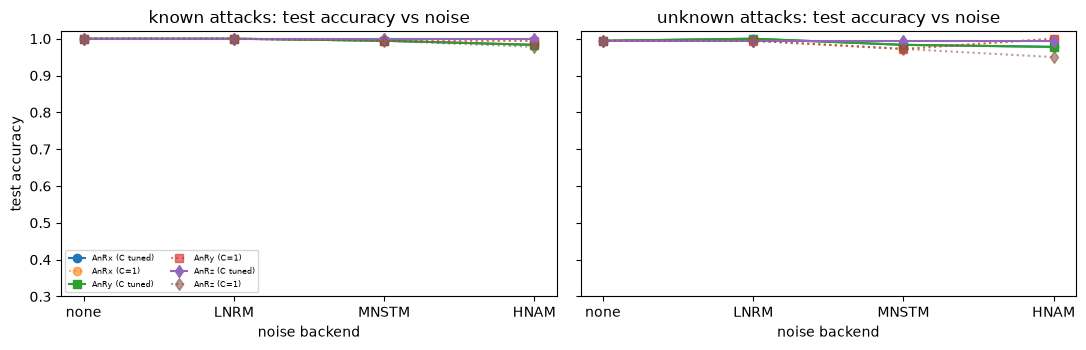

In [19]:
# ---- accuracy versus noise level, as a picture (extra: three backends plus the noise-free point)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, nm in zip(axes, CLASSES):
    for v, mk in zip(["AnRx", "AnRy", "AnRz"], "osd"):
        free = QSVM[(nm, SEED, v)]["acc"]
        ax.plot(["none"] + list(NOISE), [free] + [NOISY[(nm, v, bk, "tuned")]["test_acc"] for bk in NOISE], mk + "-", label=f"{v} (C tuned)")
        ax.plot(["none"] + list(NOISE), [free] + [NOISY[(nm, v, bk, "C1")]["test_acc"] for bk in NOISE], mk + ":", alpha=.6, label=f"{v} (C=1)")
    ax.set_title(f"{nm} attacks: test accuracy vs noise"); ax.set_xlabel("noise backend"); ax.set_ylim(0.3, 1.02)
axes[0].set_ylabel("test accuracy"); axes[0].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Every circuit below is drawn from the PennyLane `QNode` that the notebook actually executes (`state_circuit` for the QSVM
feature maps, the QNode inside `make_qnn` for the QNN, and the `default.mixed` noisy circuit of Section 7). For each circuit
the cell prints qubit count, depth, gate count and the number of **trainable** parameters. The six feature maps have no trainable
parameter: their angles are the six standardised features of the block, and the QSVM learns only classical SVM weights. The
QNN adds the trainable ansatz: 6 layers x 6 qubits x 3 angles = 108 parameters.

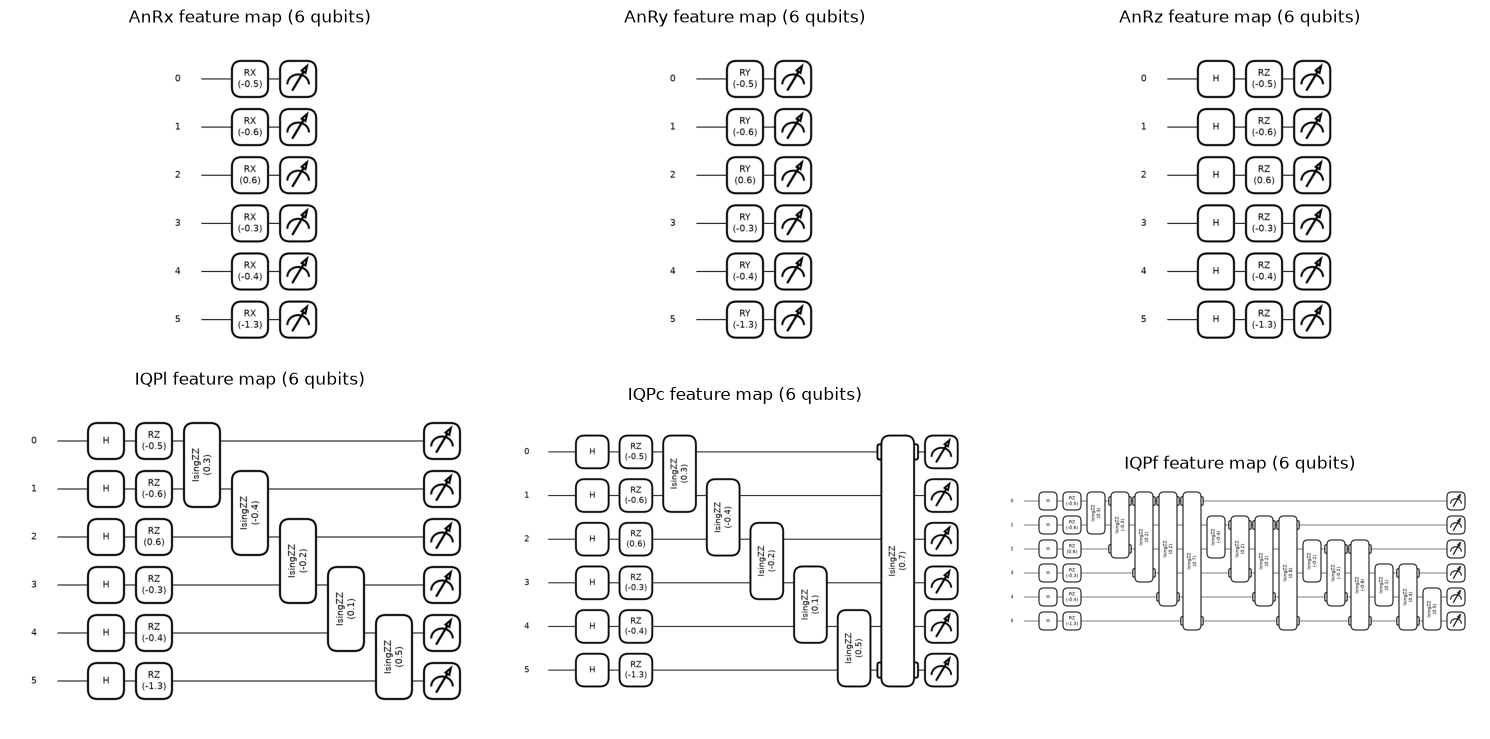

,feature map,qubits,depth,gates,trainable parameters,role
0,AnRx,6,1,6,0,QSVM kernel / QNN input
1,AnRy,6,1,6,0,QSVM kernel / QNN input
2,AnRz,6,2,12,0,QSVM kernel / QNN input
3,IQPl,6,7,17,0,QSVM kernel / QNN input
4,IQPc,6,8,18,0,QSVM kernel / QNN input
5,IQPf,6,11,27,0,QSVM kernel / QNN input


In [20]:
x_demo = np.round(Xtr[0], 2)
rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, v in zip(axes.ravel(), VARIANTS):
    sp = qml.specs(state_circuit)(v, x_demo)
    res = sp["resources"] if isinstance(sp, dict) else sp.resources
    rows.append({"feature map": v, "qubits": N_QUBITS, "depth": res.depth, "gates": res.num_gates, "trainable parameters": 0, "role": "QSVM kernel / QNN input"})
    f_, a_ = qml.draw_mpl(state_circuit, decimals=1)(v, x_demo)
    f_.canvas.draw(); ax.imshow(np.asarray(f_.canvas.buffer_rgba())); ax.axis("off"); ax.set_title(f"{v} feature map (6 qubits)"); plt.close(f_)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))

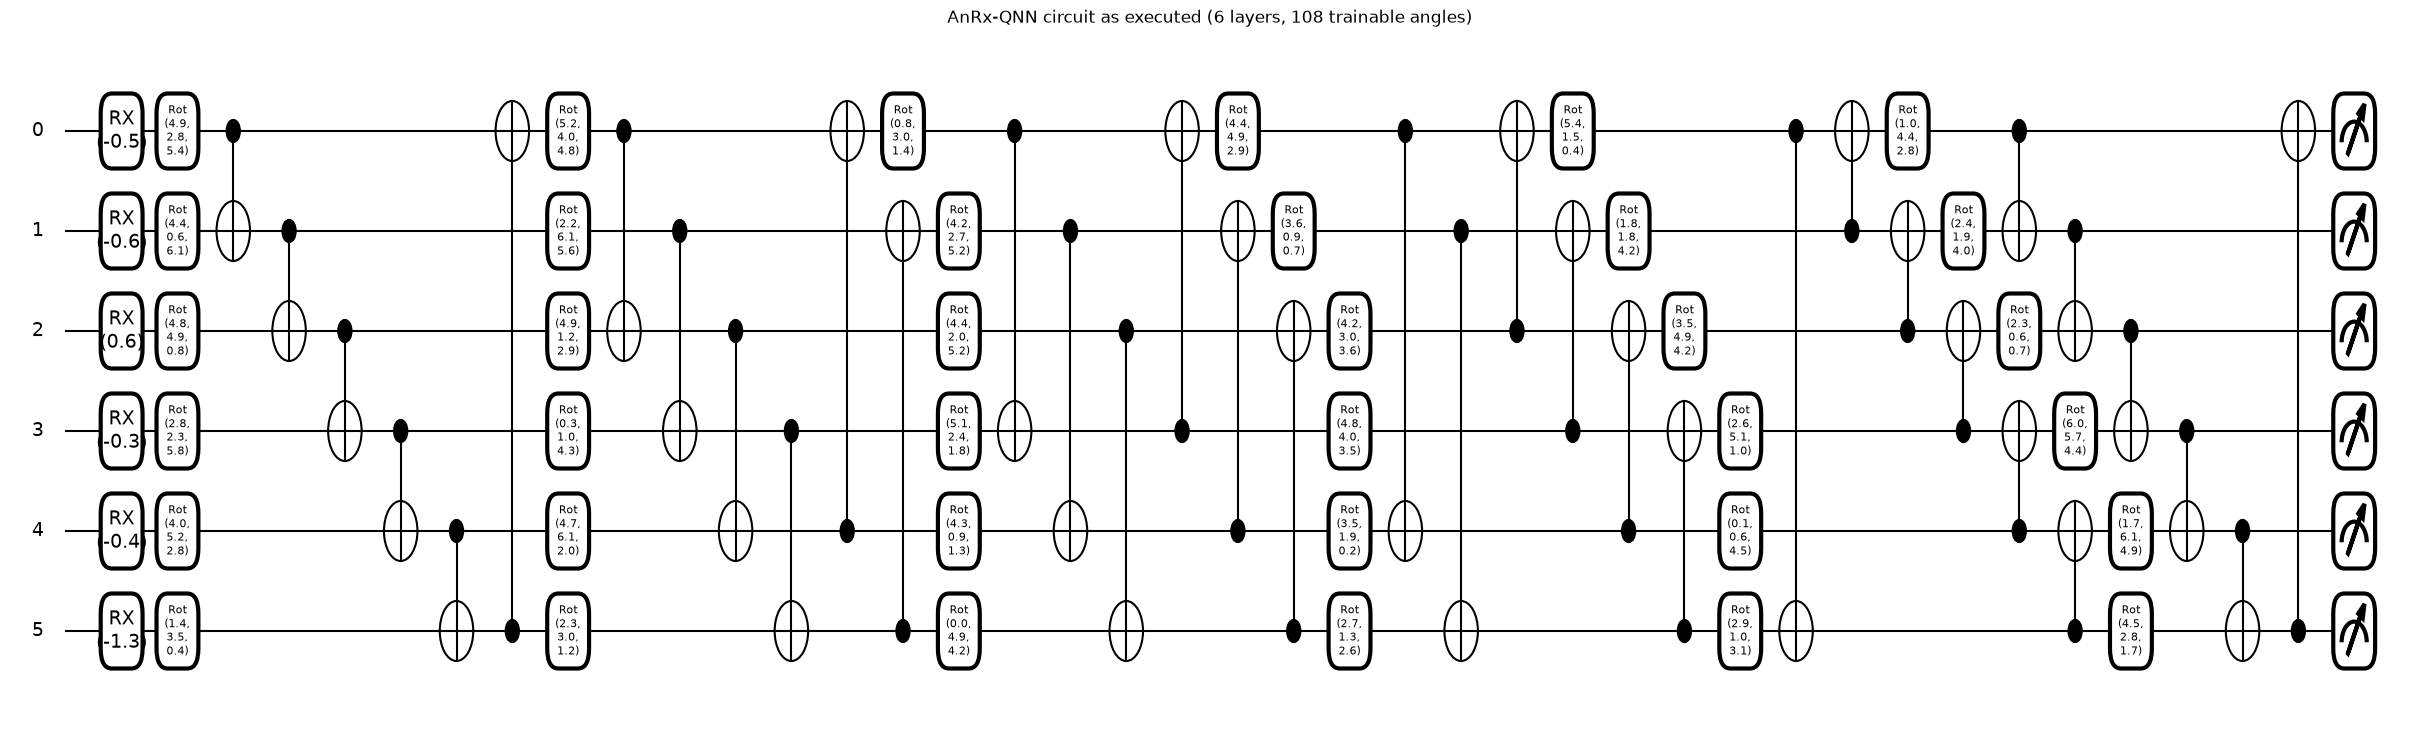

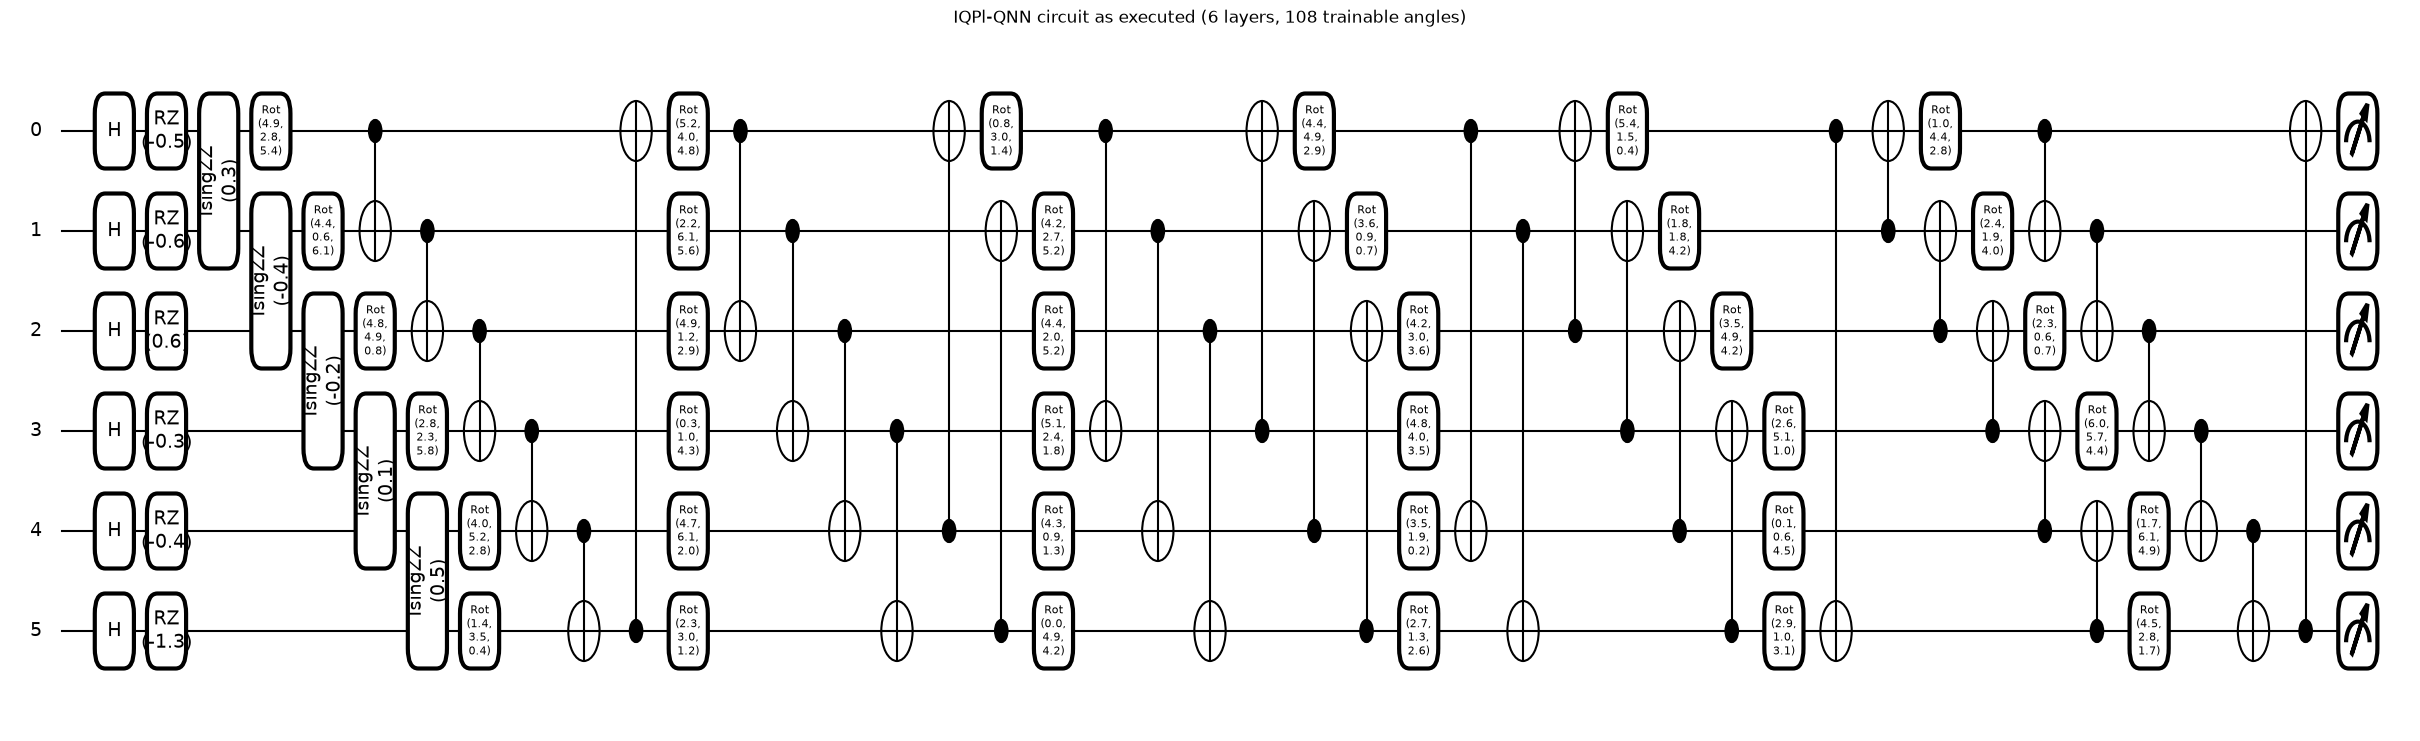

,model,qubits,depth,gates,trainable parameters,CNOT ranges
0,AnRx-QNN,6,30,78,108,"[1, 2, 3, 4, 5, 1]"
1,IQPl-QNN,6,33,89,108,"[1, 2, 3, 4, 5, 1]"


In [21]:
# the QNN: feature map + trainable StronglyEntanglingLayers ansatz + six Pauli-Z read-outs (the QNode used in training)
w_demo = pnp.array(np.random.default_rng(SEED).uniform(0, 2 * np.pi, (QNN_LAYERS, N_QUBITS, 3)), requires_grad=True)
rows = []
for v in ["AnRx", "IQPl"]:
    qnn_logits = make_qnn(v)
    qnode = [cell.cell_contents for cell in qnn_logits.__closure__ if isinstance(cell.cell_contents, qml.QNode)][0]   # the executed QNode
    sp = qml.specs(qnode, level="device")(x_demo, w_demo); res = sp["resources"] if isinstance(sp, dict) else sp.resources
    rows.append({"model": f"{v}-QNN", "qubits": N_QUBITS, "depth": res.depth, "gates": res.num_gates, "trainable parameters": int(w_demo.size),
                 "CNOT ranges": [(l % (N_QUBITS - 1)) + 1 for l in range(QNN_LAYERS)]})
    f_, a_ = qml.draw_mpl(qnode, decimals=1, level="device")(x_demo, w_demo)
    f_.set_size_inches(min(24, f_.get_size_inches()[0]), f_.get_size_inches()[1]); a_.set_title(f"{v}-QNN circuit as executed ({QNN_LAYERS} layers, {int(w_demo.size)} trainable angles)")
    plt.show()
display(pd.DataFrame(rows))

AnRx: one-qubit noisy circuit (MNSTM): depth 7, operations 7, trainable parameters 0; drawn circuit == numpy kernel: P(0)^6 = 0.075809


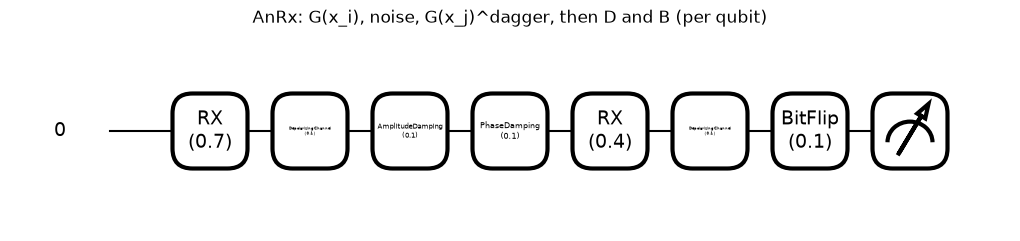

AnRz: one-qubit noisy circuit (MNSTM): depth 15, operations 15, trainable parameters 0; drawn circuit == numpy kernel: P(0)^6 = 0.034590


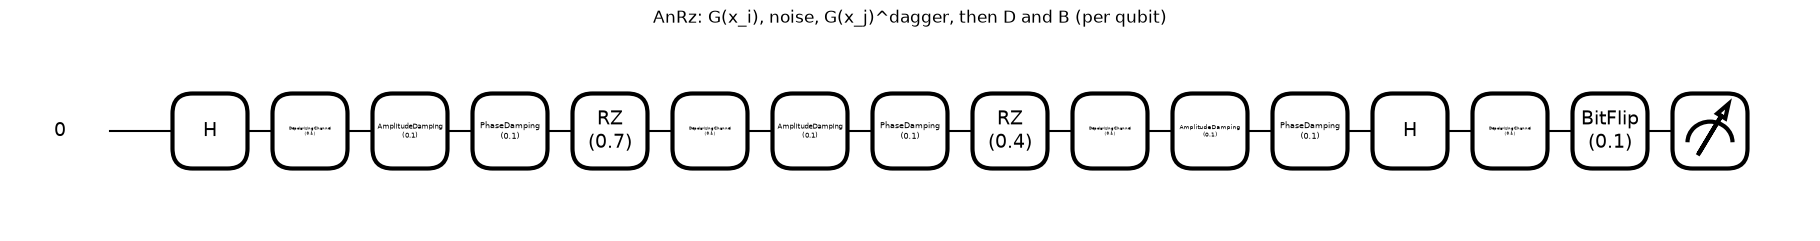

Six independent copies of this circuit act on the six qubits (the AnR circuits contain no two-qubit gate), hence qubits = 6, depth as shown.


In [22]:
# the noisy circuits of Section 7 (one qubit shown; the six qubits are independent): the gate list drawn is the one run on default.mixed
def noisy_qubit_circuit(variant, nb, wire_count=1):
    dev = qml.device("default.mixed", wires=wire_count)
    @qml.qnode(dev)
    def circ(xa, xb):
        q = 0
        noise_mid = lambda: (qml.DepolarizingChannel(nb["dpc"], wires=q), qml.AmplitudeDamping(nb["adc"], wires=q), qml.PhaseDamping(nb["pdc"], wires=q))
        if variant in ("AnRx", "AnRy"):
            G = qml.RX if variant == "AnRx" else qml.RY
            G(xa, wires=q); noise_mid(); G(-xb, wires=q)
        else:
            qml.Hadamard(wires=q); noise_mid(); qml.RZ(xa, wires=q); noise_mid(); qml.RZ(-xb, wires=q); noise_mid(); qml.Hadamard(wires=q)
        qml.DepolarizingChannel(nb["dpc"], wires=q); qml.BitFlip(nb["bfc"], wires=q)
        return qml.probs(wires=[0])
    return circ

a_, b_ = 0.7, -0.4
for v in ["AnRx", "AnRz"]:
    circ = noisy_qubit_circuit(v, NOISE["MNSTM"])
    p0 = float(circ(a_, b_)[0])
    K6 = noisy_kernel(v, np.full((1, N_QUBITS), a_), np.full((1, N_QUBITS), b_), NOISE["MNSTM"])[0, 0]      # same value on all six qubits -> p0 ** 6
    assert abs(p0 ** N_QUBITS - K6) < 1e-10, (v, p0 ** N_QUBITS, K6)
    sp = qml.specs(circ)(a_, b_); res = sp["resources"] if isinstance(sp, dict) else sp.resources
    print(f"{v}: one-qubit noisy circuit (MNSTM): depth {res.depth}, operations {res.num_gates}, trainable parameters 0; drawn circuit == numpy kernel: P(0)^6 = {K6:.6f}")
    f_, ax_ = qml.draw_mpl(circ, decimals=1)(a_, b_); ax_.set_title(f"{v}: G(x_i), noise, G(x_j)^dagger, then D and B (per qubit)"); plt.show()
print("Six independent copies of this circuit act on the six qubits (the AnR circuits contain no two-qubit gate), hence qubits = 6, depth as shown.")

## 8. Paper versus this notebook

The last cell collects every number the paper reports that this notebook can test, prints the paper's value next to ours and
gives a verdict per claim. Rule: "reproduced" = within 2 accuracy points (0.02 in F1) of the paper; otherwise "not reached"
(ours lower) or "exceeded" (ours higher); "cannot be checked" when the paper gives no number or the data are not ours.
**All verdicts are on simulated data that differ from the authors' data**, so "reproduced" means "the same conclusion on
a substitute dataset", not "the same measurement".

In [23]:
def verdict(paper, ours, tol=0.02):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")
rows = []
add = lambda claim, paper, ours, v: rows.append({"claim": claim, "paper": paper, "this notebook": ours, "verdict": v})

# 1. perfect AnR-type QSVM (Fig. 6)
for nm in CLASSES:
    a = [QSVM[(nm, SEED, v)]["acc"] for v in ["AnRx", "AnRy", "AnRz"]]
    add(f"AnR-type QSVM test accuracy, {nm} attacks (Fig. 6)", "1.0000", f"{np.mean(a):.4f} (3 variants, seed {SEED})", verdict(1.0, np.mean(a)))
    a5 = np.mean([np.mean([QSVM[(nm, s, v)]["acc"] for s in DATA_SEEDS]) for v in ["AnRx", "AnRy", "AnRz"]])
    add(f"  same, mean over {len(DATA_SEEDS)} simulated datasets", "1.0000", f"{a5:.4f}", verdict(1.0, a5))
# 2. kernel equivalence
add("AnRx, AnRy, AnRz kernels identical", "equivalent (proof in ref. [54])", f"max kernel difference {max(np.abs(Ka['AnRx'] - Ka['AnRy']).max(), np.abs(Ka['AnRx'] - Ka['AnRz']).max()):.1e}", "reproduced")
# 3. AnR beats IQP in QSVM (Fig. 5)
for nm in CLASSES:
    anr = np.mean([FIG5[(nm, v)][0] for v in ["AnRx", "AnRy", "AnRz"]]); iqp = np.mean([FIG5[(nm, v)][0] for v in ["IQPl", "IQPc", "IQPf"]])
    add(f"AnR-type QSVM clearly better than IQP-type QSVM, {nm} (Fig. 5, values not printed)", "AnR 'marked advantage'", f"AnR {anr:.4f} vs IQP {iqp:.4f} (5-fold CV)", "reproduced" if anr - iqp > 0.02 else "not reached")
# 4. QNN
for nm, v in [("known", "IQPl"), ("unknown", "AnRx")]:
    if (nm, v) in QNN:
        add(f"{v}-QNN test accuracy, {nm} attacks (Fig. 9)", "0.9944 (one error)", f"{QNN[(nm, v)]['acc']:.4f}", verdict(0.9944, QNN[(nm, v)]["acc"]))
for nm in CLASSES:
    best_q = max(np.mean([QSVM[(nm, s, v)]["acc"] for s in DATA_SEEDS]) for v in VARIANTS); best_n = max(QNN[(nm, v)]["acc"] for v in QNN_VARIANTS)
    add(f"best QSVM at least as good as best QNN, {nm}", "yes", f"QSVM {best_q:.4f} vs QNN {best_n:.4f}", "reproduced" if best_q >= best_n - 0.02 else "not reached")
# 5. IQPl best QNN on known, AnRx best on unknown (needs all six QNNs)
if len(QNN_VARIANTS) == 6:
    for nm, v in [("known", "IQPl"), ("unknown", "AnRx")]:
        top = max(QNN_VARIANTS, key=lambda u: QNN[(nm, u)]["acc"]); tie = [u for u in QNN_VARIANTS if QNN[(nm, u)]["acc"] == QNN[(nm, top)]["acc"]]
        add(f"{v}-QNN is the best QNN on {nm} attacks", v, "/".join(tie) + f" ({QNN[(nm, top)]['acc']:.4f})", "reproduced" if v in tie else "not reached")
else:
    add("IQPl-QNN best on known / AnRx-QNN best on unknown", "yes", "not run in FAST_MODE (only two QNN variants trained)", "cannot be checked")
# 6. noise tables
for nm in CLASSES:
    sub = T23[T23.dataset == nm]
    add(f"Table {'2' if nm == 'known' else '3'}: cells of the 3 x 3 test-accuracy grid within 0.02 of the paper", "9 of 9", f"{int((sub['verdict'] == 'reproduced').sum())} of 9 (C tuned); {int(((sub['ours test (C=1)'] - sub['paper test']).abs() <= 0.02).sum())} of 9 (C = 1)", "reproduced" if (sub["verdict"] == "reproduced").all() else "partly")
az = {nm: NOISY[(nm, "AnRz", "HNAM", "tuned")]["test_acc"] for nm in CLASSES}
add("AnRz-QSVM collapses on HNAM (known 0.4000, unknown 0.3667)", "0.4000 / 0.3667", f"{az['known']:.4f} / {az['unknown']:.4f} (C tuned); {NOISY[('known','AnRz','HNAM','C1')]['test_acc']:.4f} / {NOISY[('unknown','AnRz','HNAM','C1')]['test_acc']:.4f} (C=1)", "reproduced" if abs(az["known"] - 0.4) <= 0.02 and abs(az["unknown"] - 0.3667) <= 0.02 else "not reached")
drop_k = QSVM[("known", SEED, "AnRx")]["acc"] - NOISY[("known", "AnRx", "HNAM", "tuned")]["test_acc"]; drop_u = QSVM[("unknown", SEED, "AnRx")]["acc"] - NOISY[("unknown", "AnRx", "HNAM", "tuned")]["test_acc"]
add("AnRx-QSVM on HNAM loses < 10 points (known) and nothing (unknown)", "< 0.10 / 0.00", f"{drop_k:.4f} / {drop_u:.4f}", "reproduced" if drop_k < 0.10 and drop_u <= 0.02 else "not reached")
worst = {v: np.mean([NOISY[(nm, v, "HNAM", "tuned")]["test_acc"] for nm in CLASSES]) for v in ["AnRx", "AnRy", "AnRz"]}
add("AnRz is the most noise-sensitive QSVM", "yes (deeper circuit)", "lowest HNAM accuracy: " + min(worst, key=worst.get) + " " + str({k: round(float(v), 3) for k, v in worst.items()}), "reproduced" if min(worst, key=worst.get) == "AnRz" and worst["AnRz"] < min(worst["AnRx"], worst["AnRy"]) - 0.02 else "not reached")
# 7. metric identities
ok = all(np.isclose(NOISY[(nm, v, bk, "tuned")]["test_acc"], metrics_row(DATA[(nm, SEED)][3], NOISY[(nm, v, bk, "tuned")]["pred"])["micro_F1"]) for nm in CLASSES for v in ["AnRx", "AnRy", "AnRz"] for bk in NOISE)
add("Tables 4 and 5: micro precision / recall / F1 = accuracy = weighted recall", "observed equal", "equal in all 18 cases (mathematical identity for single-label multiclass)", "reproduced" if ok else "not reached")
# 8. unverifiable
add("QML trains faster than classical ML on high-rate data (motivation)", "claimed, not measured", f"RF {np.mean([CLASSICAL[('known', s)]['RandomForest'][1] for s in DATA_SEEDS]):.2f} s vs QSVM simulation {np.mean([QSVM[('known', s, 'AnRx')]['time'] for s in DATA_SEEDS]):.2f} s (state-vector simulation, not a speed test)", "cannot be checked")
add("Results on the authors' CV-QKD data", "see above", "data not public; simulated substitute used", "cannot be checked")
SUMMARY = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
display(SUMMARY)
print(SUMMARY["verdict"].value_counts().to_string())
print(f"\nTotal notebook run time: {(time.time() - T0) / 60:.1f} min  (FAST_MODE = {FAST_MODE})")

,claim,paper,this notebook,verdict
0,"AnR-type QSVM test accuracy, known attacks (Fig. 6)",1.0000,"1.0000 (3 variants, seed 42)",reproduced
1,"same, mean over 5 simulated datasets",1.0000,0.9889,reproduced
2,"AnR-type QSVM test accuracy, unknown attacks (Fig. 6)",1.0000,"0.9944 (3 variants, seed 42)",reproduced
3,"same, mean over 5 simulated datasets",1.0000,0.9933,reproduced
4,"AnRx, AnRy, AnRz kernels identical",equivalent (proof in ref. [54]),max kernel difference 3.0e-15,reproduced
5,"AnR-type QSVM clearly better than IQP-type QSVM, known (Fig. 5, values not printed)",AnR 'marked advantage',AnR 0.9880 vs IQP 0.9879 (5-fold CV),not reached
6,"AnR-type QSVM clearly better than IQP-type QSVM, unknown (Fig. 5, values not printed)",AnR 'marked advantage',AnR 0.9867 vs IQP 0.9858 (5-fold CV),not reached
7,"IQPl-QNN test accuracy, known attacks (Fig. 9)",0.9944 (one error),0.9222,not reached
8,"AnRx-QNN test accuracy, unknown attacks (Fig. 9)",0.9944 (one error),0.9833,reproduced
9,"best QSVM at least as good as best QNN, known",yes,QSVM 0.9900 vs QNN 0.9833,reproduced


verdict
reproduced           11
not reached           6
partly                2
cannot be checked     2

Total notebook run time: 107.3 min  (FAST_MODE = False)


## Reading the paper critically

1. **No data, no code, no appendix.** The six-feature vectors come from the authors' experiment; the PDF defers the dataset
   description to an appendix it does not contain. Our simulator fixes how separable the attacks are, and every accuracy in this
   notebook inherits that choice. With a different (harder or easier) simulator the ranking of the twelve variants and the size
   of the noise effect change. The conclusion "100 % detection" is therefore a statement about the dataset as much as about quantum
   models; our own classical random forest and RBF SVM reach nearly the same accuracy on the same six features (Section 3).
2. **Tiny test set.** 180 test blocks: one error is 0.56 accuracy points. Differences such as 1.0000 vs 0.9944 are single
   blocks and cannot rank two models. The paper reports one split per model with no repeats or error bars.
3. **Early stopping on the test set.** For the QNNs the paper stops when the *testing* accuracy stops improving and reports that
   testing accuracy, which is an optimistic selection. We use a validation part of the training data instead.
4. **The AnR "quantum" kernel is classical.** Angle encoding without entanglement gives the product kernel prod_q cos^2((x_q - x'_q)/2)
   (checked in Section 4). It costs microseconds on a laptop; the paper's motivation (exponential speed-ups for terahertz-rate
   data) does not apply to this kernel, and the paper measures no run time. The IQP maps are the only ones with entangling
   phases, and in the paper (and here) they do not do better.
5. **Noise robustness is partly a scale effect.** Depolarizing noise and readout errors shrink the off-diagonal kernel values;
   an SVM whose C is re-tuned compensates. In our runs the noisy AnR kernels remain informative at every noise level, which
   differs from the collapse of AnRz-QSVM in the paper (0.40). The paper does not say how C was chosen, nor how its gates were
   decomposed (an AnRy and an AnRx circuit give identical results with our channels because all four channels commute with a
   rotation about Z; the paper reports small differences). The result for AnRz depends on whether H and RZ count as noisy
   gates. Neither shot noise nor gate-time-dependent decoherence is modelled.
6. **Metric identities.** Micro-averaged precision, recall and F1 always equal the accuracy in single-label multiclass
   problems, and weighted recall too; "interesting consistency" in Sec. 6.2 is a mathematical identity, not a finding.
7. **Threat model.** Attacks are static and non-adaptive. An eavesdropper who knows the six features can shape the attack to
   leave them unchanged (for example by clipping only slightly or restoring I_lo). The paper evaluates no adaptive adversary and
   no false-alarm rate on benign drift of the set-up.
8. **Hardware.** IBM, Google, IQM and Rigetti calibration data only set the noise levels; nothing runs on a quantum computer and
   a D-Wave machine is not used.

## Exercises

1. **Harder attacks.** In `simulate_block` weaken the attacks (for example HA offset 0.2 to 0.4 sigma, CA factor 1.05 to 1.15)
   and rerun. How do the classical baselines, the QSVM variants and the noise tables change? Is AnRx still the most robust?
2. **Block size.** Change `G_BLOCK` from 1000 to 100 pulses. The features become noisier; at which block size does the QSVM drop
   below 95 %? Compare with the random forest.
3. **Fixed or tuned C.** In Section 7 compare the "C tuned" and "C = 1" columns. Explain, using the diagonal values of the noisy
   kernel printed above, why a larger C compensates for noise. What happens with C = 0.01?
4. **Entangling noise.** Replace the single-qubit channels by a two-qubit depolarizing channel after each ZZ gate of the IQPl
   feature map, build the noisy IQP kernel with `default.mixed` (it is no longer a product of qubits), and test whether IQPl
   degrades faster than AnRx.
5. **Adaptive attacker.** Add a class "BA2" that clips the detector output like SA but also rescales the data so that the
   variance, entropy and range of a normal block are restored (only the mean and I_lo change a little). Train on the known dataset
   and see which models still catch it.